# The Indie Game Survival Guide: What Makes an Indie Game Succeed on Steam?

**Team:** Ana, Azada, Samuel Brooks Peñaloza, Theo, Orestis

**Module:** UCL MSIN0166 Data Engineering 2025/26

---

*TODO: Write introductory paragraph covering the research question, motivation, and dataset overview (1,216 indie games from 8 data sources, stored in PostgreSQL + MongoDB, processed with Spark, analysed with DuckDB).*

## 2. Pipeline Architecture

*TODO: Describe the end-to-end pipeline flow: Data Collection (8 sources) -> Storage (PostgreSQL + MongoDB) -> Processing (Spark) -> Analytical Storage (Parquet) -> Analysis (DuckDB) -> Visualisation (this notebook).*

*TODO: Include Mermaid architecture diagram or exported image below.*

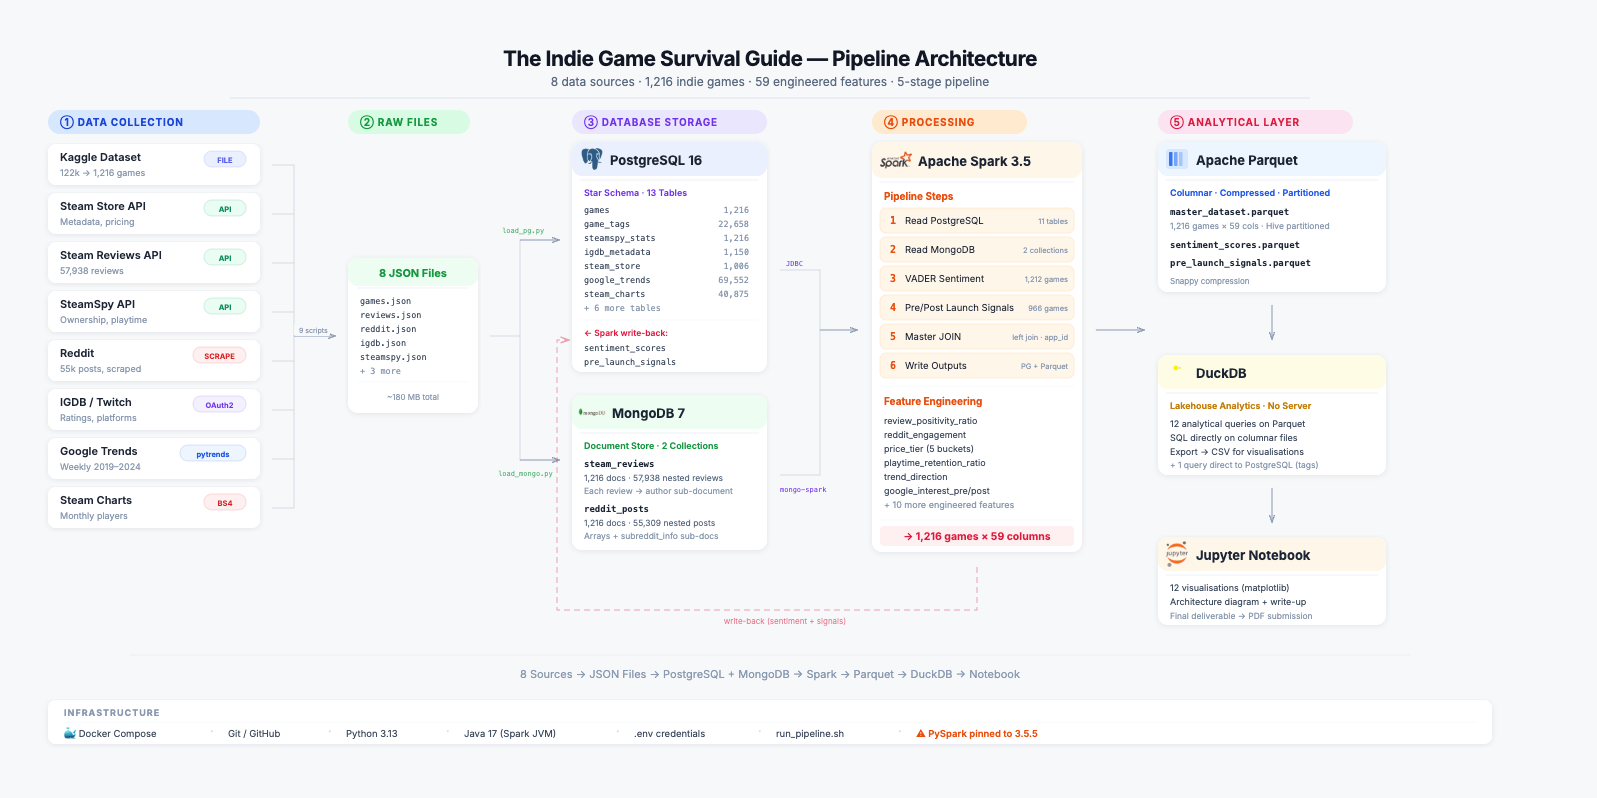

In [1]:
#pipeline architecture
from IPython.display import Image, display
display(Image('pipeline_notebook_images/pipeline_architecture.png', width=1600))

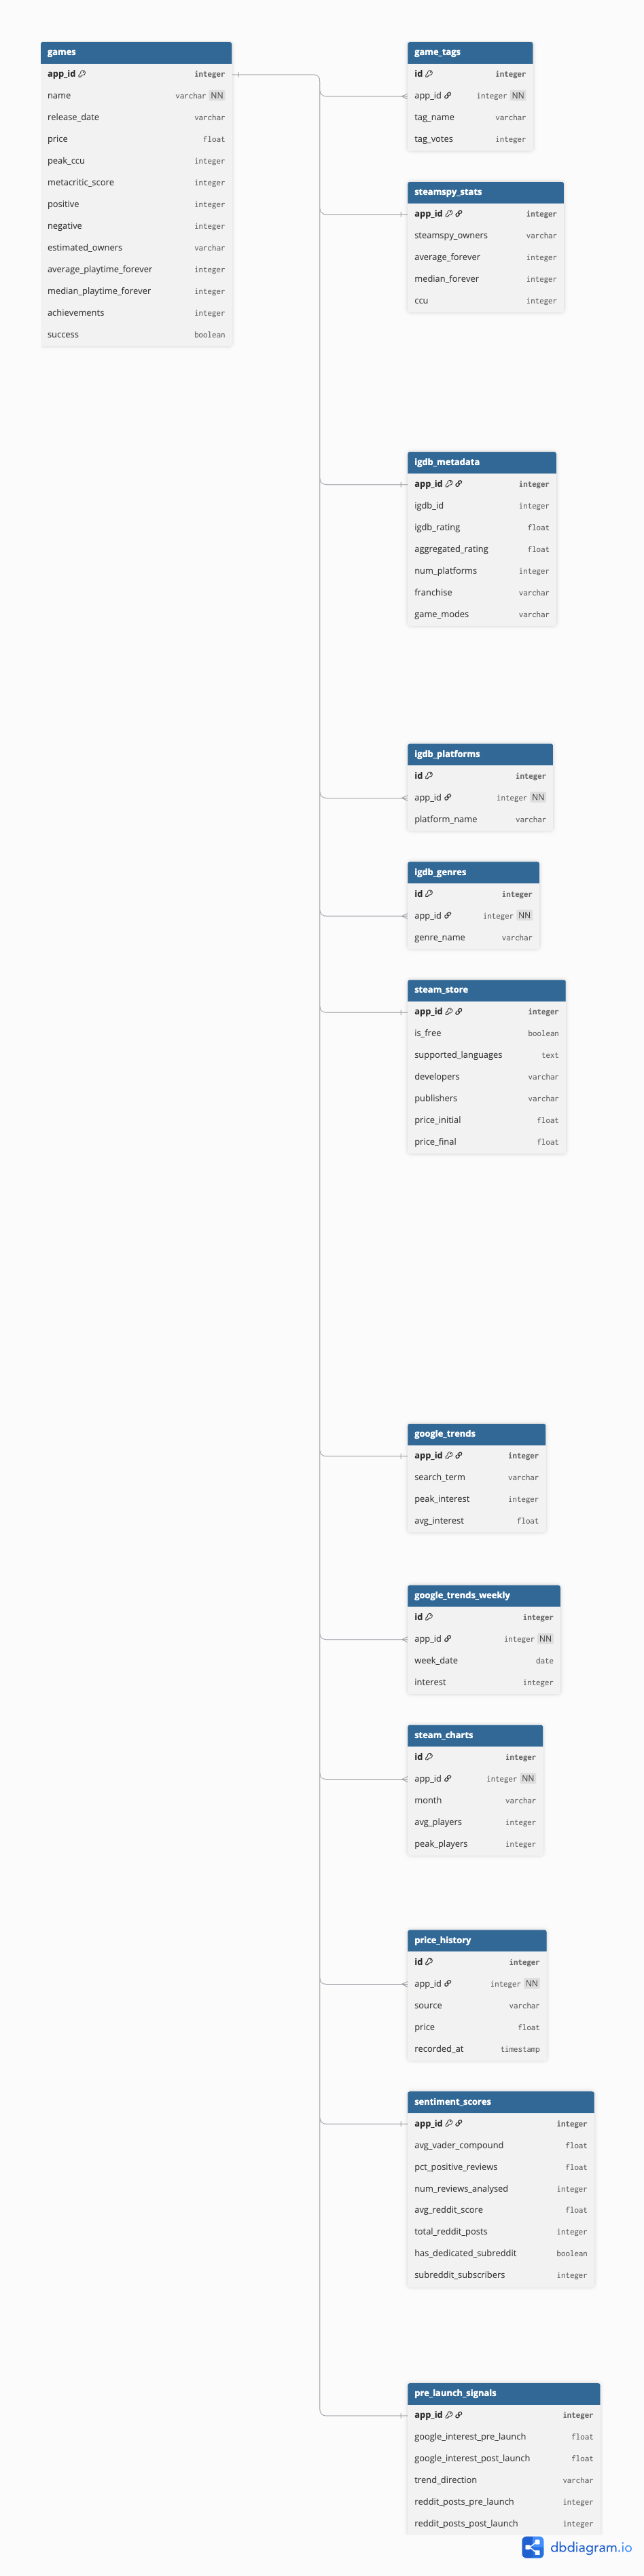

In [2]:
#postgres schema
display(Image('pipeline_notebook_images/postgres_schema.png', width=1200))

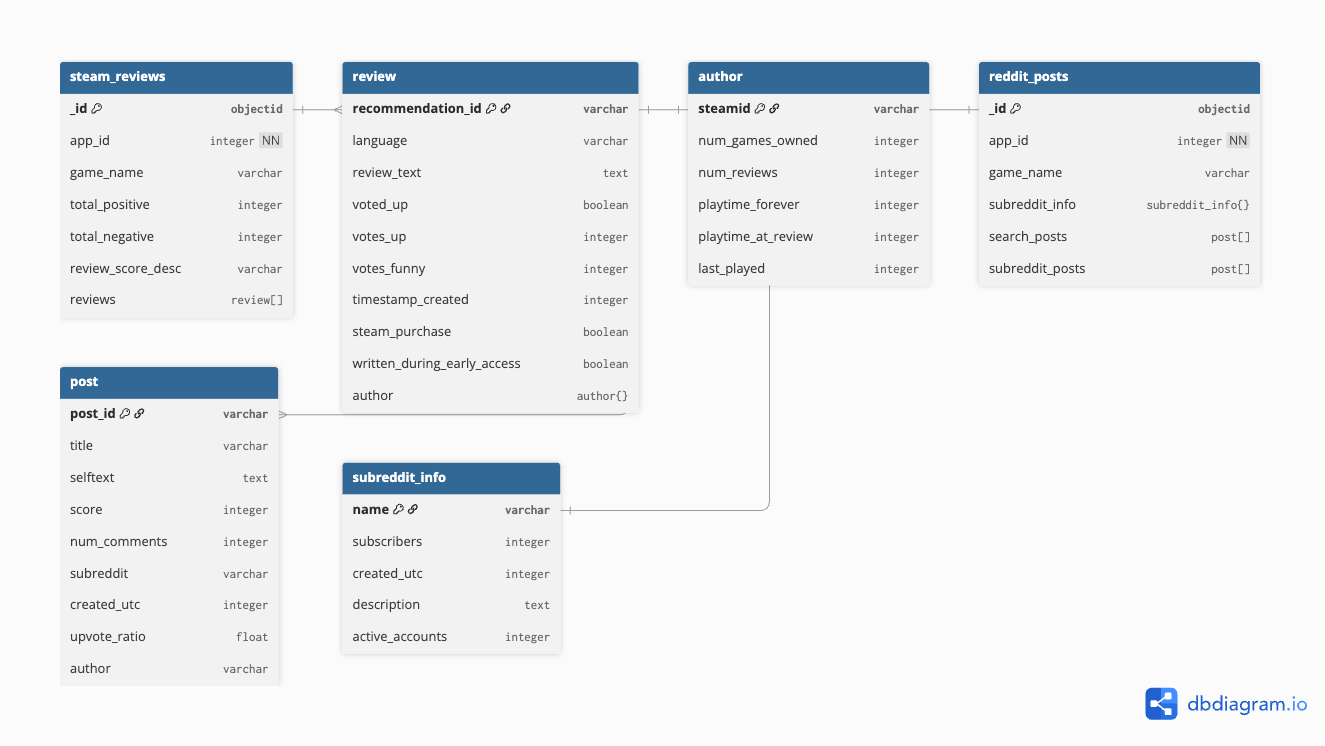

In [3]:
#mongodb schema
display(Image('pipeline_notebook_images/mongodb_schema.png', width=1600))

## 3. Data Sources

*TODO: Brief intro paragraph about data source variety (APIs, web scraping, flat files).*

| # | Source | Type | Auth | Records | Key Fields |
|---|--------|------|------|---------|------------|
| 1 | Kaggle Steam Dataset | Flat file (JSON) | None | 122,611 (filtered to 1,216) | app_id, name, price, peak_ccu, genres, tags |
| 2 | Steam Store API | REST API | None | 1,006 | descriptions, categories, platforms, metacritic |
| 3 | Steam Reviews API | REST API | None | 57,938 reviews | review text, voted_up, playtime, author stats |
| 4 | SteamSpy API | REST API | None | 1,216 | ownership estimates, playtime, CCU |
| 5 | Reddit JSON endpoints | Web scraping | None | ~55,127 posts | post title, score, comments, subreddit info |
| 6 | IGDB via Twitch | REST API | OAuth2 | 1,150 | ratings, platforms, genres, game modes |
| 7 | Google Trends | pytrends | None | 1,216 | weekly search interest 2019–2024 |
| 8 | Steam Charts | Web scraping (BS4) | None | 40,875 data points | monthly player counts |


Storage & Processing Design Rationale
PostgreSQL — structured data that needs cross-source joins.

Star schema with games as the hub, 12 satellite tables joining via app_id
Normalised tables for tags, platforms, and genres enable proper SQL queries rather than parsing comma-separated strings
Time-series data (Google Trends weekly, Steam Charts monthly) fits naturally into consistent row/column format
Follows Kimball's dimensional modelling — central fact table surrounded by descriptive dimensions (Kimball & Ross, 2013)

MongoDB — nested, variable-structure data where the unit of access is one game.

Steam reviews are deeply nested: game → reviews array → author sub-document, with 0–100 reviews per game
Reddit posts follow the same pattern: game → post arrays → optional subreddit info sub-document
Flattening into relational tables would require expensive multi-table joins for every per-game lookup
Document model maps directly to the JSON returned by the APIs, preserving the natural data shape (Sadalage & Fowler, 2012)

Apache Spark — distributed processing engine for joins, transforms, and sentiment analysis.

Reads from both PostgreSQL (JDBC) and MongoDB (mongo-spark-connector) in a single pipeline, bridging the two storage systems
In-memory processing makes the 6-step pipeline (read → sentiment → signals → join → engineer → write) run in ~12 seconds across 1,216 games
Left join across all sources on app_id would be cumbersome in raw SQL across two different databases — Spark unifies this
Designed for horizontal scaling — while our dataset fits on one machine, the same pipeline would scale to millions of games on a cluster without code changes (Zaharia et al., 2016)
VADER sentiment analysis on 57,938 reviews benefits from Spark's ability to distribute row-level UDF computation

Apache Parquet — columnar analytical storage.

Columnar format means queries that touch a few columns (e.g. "average price by success") only read those columns, not all 59
Snappy compression reduces the master dataset from ~180 MB raw JSON to compact Parquet files
Hive-partitioned by success for efficient filtered reads
Serves as the bridge between Spark (write) and DuckDB (read) — a standard lakehouse pattern (Armbrust et al., 2021)

DuckDB — serverless analytical SQL on Parquet files.

Runs SQL directly on Parquet with no database server to manage — zero infrastructure overhead
12 analytical queries execute in milliseconds, demonstrating the lakehouse pattern where storage (Parquet) is decoupled from compute (DuckDB)
Complements PostgreSQL: DuckDB handles analytical aggregations on the full 59-column dataset, PostgreSQL handles relational tag queries

We chose each tool for what it handles what it's best at — PostgreSQL for relational joins, MongoDB for nested documents, Spark for cross-database processing at scale, Parquet for efficient analytical storage, DuckDB for lightweight SQL analytics. No single tool could cover all five roles.

## 4. Schema Design

### PostgreSQL (13 tables)

*TODO: Describe the star schema with `games` as the hub table. List all 13 tables: games, game_tags, steamspy_stats, igdb_metadata, igdb_platforms, igdb_genres, steam_store, google_trends, google_trends_weekly, steam_charts, price_history, sentiment_scores, pre_launch_signals. Mention the game_overview view.*

*TODO: Discuss normalisation decisions (e.g., game_tags as separate table vs comma-separated string, igdb_platforms/genres normalised for proper relational queries).*

### MongoDB (2 collections)

*TODO: Describe document model for steam_reviews (1,216 docs, nested reviews array with author sub-documents) and reddit_posts (1,216 docs, search_posts + subreddit_posts arrays). Explain why nested documents suit this data better than relational tables.*

## 5. Spark Pipeline

*TODO: Explain the 6-step pipeline: read PostgreSQL (JDBC) + MongoDB (mongo-spark-connector) -> VADER sentiment analysis -> pre/post launch signals -> master dataset join -> feature engineering -> write to Parquet + PostgreSQL.*

*TODO: Mention key technical decisions (PySpark 3.5.5, explicit StructType schema, Row.asDict(recursive=True)).*

In [4]:
# Load the master dataset exported by DuckDB
import pandas as pd

df = pd.read_csv('../storage/master_dataset.csv')
print(f"Dataset: {df.shape[0]} games x {df.shape[1]} columns")
df.head()

Dataset: 1216 games x 62 columns


,app_id,name,release_date,required_age,price,dlc_count,short_description,windows,mac,linux,...,review_positivity_ratio,price_tier,steam_platform_count,num_supported_languages,playtime_retention_ratio,reddit_engagement,has_franchise,owners_estimate,success_tier,tier_rank
0,4000,Garry's Mod,"Nov 29, 2006",0,4.99,0,Garry's Mod is a physics sandbox. There aren't...,True,True,True,...,0.968,under_5,3,31,0.135,237108.98,False,35000000.0,Breakout Hit,1
1,4920,Natural Selection 2,"Oct 30, 2012",0,0.99,10,A fast paced multiplayer shooter that pits ali...,True,False,False,...,0.853,under_5,1,10,0.189,6617640.46,False,1500000.0,Breakout Hit,1
2,16900,GROUND BRANCH,"Aug 14, 2018",0,25.49,0,From one of the developers behind the original...,True,False,False,...,0.893,15_to_30,1,0,0.415,858368.74,False,1500000.0,Breakout Hit,1
3,18500,Defense Grid: The Awakening,"Dec 8, 2008",0,2.49,6,Defense Grid: The Awakening is a unique spin o...,True,False,False,...,0.962,under_5,1,5,0.207,NaN,False,750000.0,Strong Success,2
4,22100,Mount & Blade,"Nov 3, 2008",0,2.49,0,"Calradia is a land at war, offering great rich...",True,False,False,...,0.923,under_5,1,6,0.238,1791389.11,False,750000.0,Strong Success,2


## 6. DuckDB Analysis

The following 12 queries run directly on Parquet files using DuckDB (Lakehouse pattern). Q11 queries PostgreSQL for normalised tag data.

In [5]:
import duckdb, pandas as pd, warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('../storage/master_dataset.csv')
con = duckdb.connect()
con.register('games', df)
print(f"Loaded: {df.shape[0]} games x {df.shape[1]} columns")

# ── Success tier thresholds (based on SteamSpy owners_estimate) ──
# Breakout Hit      : 1,000,000+ owners  — viral, culturally significant
# Strong Success    :   200,000–999,999  — commercially healthy, healthy community
# Moderate Success  :    20,000–199,999  — viable, recouped costs
# Underperformer    :         < 20,000   — failed to find audience
TIERS = ['Breakout Hit', 'Strong Success', 'Moderate Success', 'Underperformer']
TIER_COLORS = {
    'Breakout Hit':      '#7c3aed',
    'Strong Success':    '#2563eb',
    'Moderate Success':  '#16a34a',
    'Underperformer':    '#ef4444',
}

# ── owners_estimate guard ────────────────────────────────────────────────────
# owners_estimate is produced by spark_pipeline.py. If the pipeline has not
# been re-run yet, fall back to a rough estimate so the notebook still runs:
#   - success=True  → 50,000 (midpoint of the 20k–200k "Moderate Success" band)
#   - success=False → 5,000  (midpoint of the "<20k" Underperformer band)
# Re-run spark_pipeline.py to get real per-game estimates.
if 'owners_estimate' not in df.columns:
    print("WARNING: owners_estimate not found in CSV — using fallback estimates.")
    print("         Re-run spark_pipeline.py to get accurate SteamSpy-derived values.")
    df['owners_estimate'] = df['success'].map({True: 50_000, False: 5_000})

# ── success_tier guard ───────────────────────────────────────────────────────
# Also derived by spark_pipeline.py. Recompute here if missing.
if 'success_tier' not in df.columns:
    def assign_tier(o):
        if o >= 1_000_000: return 'Breakout Hit'
        if o >=   200_000: return 'Strong Success'
        if o >=    20_000: return 'Moderate Success'
        return 'Underperformer'
    df['success_tier'] = df['owners_estimate'].apply(assign_tier)
    con.register('games', df)  # re-register with new columns

# Re-register after any column additions
con.register('games', df)

print("\nTier breakdown (using owners_estimate from SteamSpy):")
for tier in TIERS:
    if tier == 'Breakout Hit':
        n = (df['owners_estimate'] >= 1_000_000).sum()
    elif tier == 'Strong Success':
        n = ((df['owners_estimate'] >= 200_000) & (df['owners_estimate'] < 1_000_000)).sum()
    elif tier == 'Moderate Success':
        n = ((df['owners_estimate'] >= 20_000) & (df['owners_estimate'] < 200_000)).sum()
    else:
        n = (df['owners_estimate'] < 20_000).sum()
    print(f"  {tier:20s}: {n:4d} games")


Loaded: 1216 games x 62 columns

Tier breakdown (using owners_estimate from SteamSpy):
  Breakout Hit        :  368 games
  Strong Success      :  490 games
  Moderate Success    :  255 games
  Underperformer      :  103 games


In [6]:
# Q1: Four-tier success landscape of the 1,216 indie games.
# Tiers are defined on SteamSpy owners_estimate (more granular than the binary 20k flag):
#   Breakout Hit      ≥ 1,000,000 owners  — cultural phenomenon
#   Strong Success    ≥   200,000 owners  — commercially healthy
#   Moderate Success  ≥    20,000 owners  — viable, cost-recovering
#   Underperformer    <    20,000 owners  — failed to find audience
# Compares avg price, peak CCU, review positivity, and Metacritic across tiers.

q1 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT success_tier, COUNT(*) AS num_games,
        ROUND(AVG(price), 2)                    AS avg_price,
        ROUND(AVG(peak_ccu), 0)                 AS avg_peak_ccu,
        ROUND(AVG(positive), 0)                 AS avg_positive_reviews,
        ROUND(AVG(negative), 0)                 AS avg_negative_reviews,
        ROUND(AVG(review_positivity_ratio), 3)  AS avg_review_ratio,
        ROUND(AVG(metacritic_score), 1)         AS avg_metacritic,
        ROUND(AVG(owners_estimate), 0)          AS avg_owners
    FROM tiered
    GROUP BY success_tier, tier_rank
    ORDER BY tier_rank
""").df()
display(q1)


,success_tier,num_games,avg_price,avg_peak_ccu,avg_positive_reviews,avg_negative_reviews,avg_review_ratio,avg_metacritic,avg_owners
0,Breakout Hit,368,7.25,3335.0,89872.0,7681.0,0.899,34.6,4769022.0
1,Strong Success,490,8.83,383.0,9278.0,1274.0,0.871,19.6,547551.0
2,Moderate Success,255,9.77,237.0,1703.0,244.0,0.851,6.0,102000.0
3,Underperformer,103,8.18,2058.0,287.0,48.0,0.834,2.3,10000.0


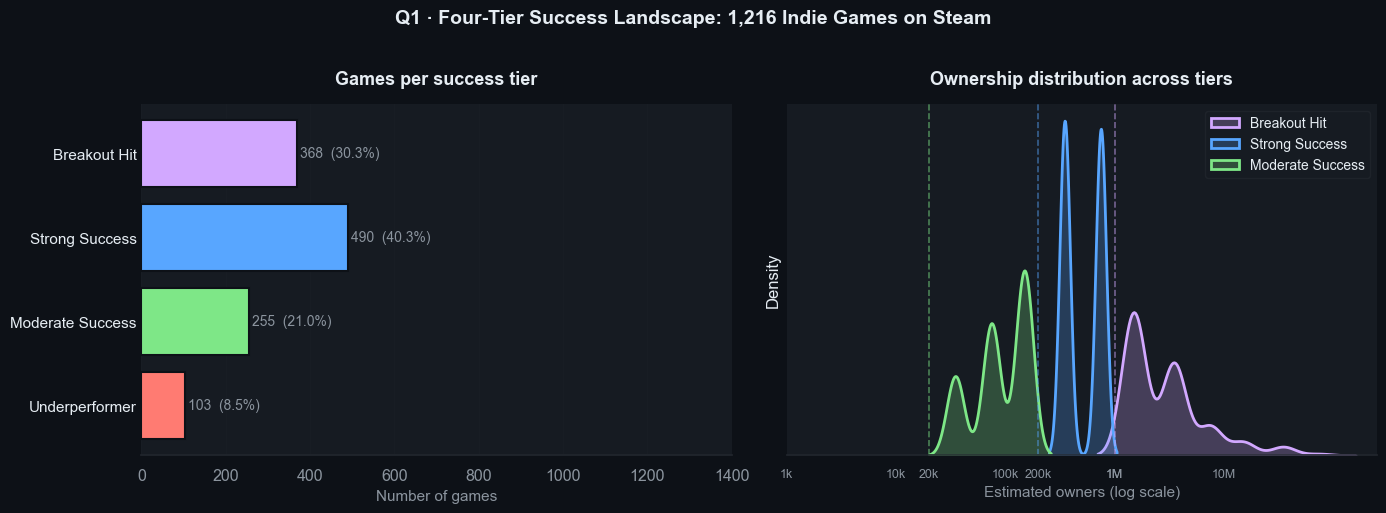

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Theme ─────────────────────────────────────────────────────────────────────
BG    = '#0D1117'
CARD  = '#161B22'
GRID  = '#21262D'
TEXT  = '#E6EDF3'
SUBTEXT = '#8B949E'

plt.rcParams.update({
    'figure.facecolor':  BG,
    'axes.facecolor':    CARD,
    'axes.edgecolor':    GRID,
    'axes.labelcolor':   TEXT,
    'axes.titlepad':     16,
    'text.color':        TEXT,
    'xtick.color':       SUBTEXT,
    'ytick.color':       SUBTEXT,
    'grid.color':        GRID,
    'grid.alpha':        0.4,
    'font.family':       'sans-serif',
    'font.size':         11,
    'axes.titlesize':    15,
    'axes.labelsize':    12,
    'figure.titlesize':  18,
    'legend.facecolor':  CARD,
    'legend.edgecolor':  GRID,
    'legend.fontsize':   10,
})

# Tier palette mapped to neon accents
tier_order  = ['Breakout Hit', 'Strong Success', 'Moderate Success', 'Underperformer']
tier_colors = ['#D2A8FF', '#58A6FF', '#7EE787', '#FF7B72']   # purple, blue, green, red

def assign_tier(row):
    o = row.get('owners_estimate', 0) or 0
    if o >= 1_000_000: return 'Breakout Hit'
    if o >= 200_000:   return 'Strong Success'
    if o >= 20_000:    return 'Moderate Success'
    return 'Underperformer'

df['success_tier'] = df.apply(assign_tier, axis=1)
tier_counts = df['success_tier'].value_counts().reindex(tier_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=BG)
fig.patch.set_facecolor(BG)

# ── Left: horizontal bar chart ─────────────────────────────────────────────
bars = axes[0].barh(
    tier_order[::-1], tier_counts[tier_order[::-1]],
    color=tier_colors[::-1], edgecolor=BG, linewidth=1.5
)
for bar, count in zip(bars, tier_counts[tier_order[::-1]]):
    axes[0].text(
        bar.get_width() + 8, bar.get_y() + bar.get_height() / 2,
        f'{count:,}  ({count/1216*100:.1f}%)',
        va='center', fontsize=10, color=SUBTEXT
    )
axes[0].set_xlim(0, 1400)
axes[0].set_xlabel('Number of games', fontsize=11, color=SUBTEXT)
axes[0].set_title('Games per success tier', fontsize=13, fontweight='600', color=TEXT, pad=14)
axes[0].tick_params(axis='y', labelsize=11, colors=TEXT)
axes[0].tick_params(axis='x', colors=SUBTEXT)
axes[0].set_facecolor(CARD)
for spine in axes[0].spines.values():
    spine.set_edgecolor(GRID)
axes[0].spines['left'].set_visible(False)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].yaxis.set_tick_params(length=0)
axes[0].grid(True, axis='x', alpha=0.2, color=GRID)

# ── Right: ownership KDE distribution ─────────────────────────────────────
for tier, color in zip(tier_order, tier_colors):
    vals = df.loc[df.success_tier == tier, 'owners_estimate'].dropna()
    vals = vals[vals > 0]
    if len(vals) > 1:
        sns.kdeplot(np.log10(vals), ax=axes[1], color=color, fill=True,
                    alpha=0.25, linewidth=2, label=tier)

# Threshold lines
axes[1].axvline(np.log10(20_000),    color='#7EE787', ls='--', lw=1.2, alpha=0.5)
axes[1].axvline(np.log10(200_000),   color='#58A6FF', ls='--', lw=1.2, alpha=0.5)
axes[1].axvline(np.log10(1_000_000), color='#D2A8FF', ls='--', lw=1.2, alpha=0.5)

axes[1].set_xticks([3, 4, np.log10(20_000), 5, np.log10(200_000), 6, np.log10(1_000_000), 7])
axes[1].set_xticklabels(['1k', '10k', '20k', '100k', '200k', '1M', '1M', '10M'],
                         fontsize=9, color=SUBTEXT)
axes[1].set_xlabel('Estimated owners (log scale)', fontsize=11, color=SUBTEXT)
axes[1].set_yticks([])
axes[1].set_title('Ownership distribution across tiers', fontsize=13, fontweight='600',
                   color=TEXT, pad=14)
axes[1].legend(fontsize=10, frameon=True, facecolor=CARD, edgecolor=GRID, labelcolor=TEXT)
axes[1].set_facecolor(CARD)
for spine in axes[1].spines.values():
    spine.set_edgecolor(GRID)
axes[1].spines['left'].set_visible(False)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

fig.suptitle(
    'Q1 · Four-Tier Success Landscape: 1,216 Indie Games on Steam',
    fontsize=14, fontweight='700', color=TEXT, y=1.02
)
plt.tight_layout()
plt.show()

placeholder

In [8]:
# Q2: Price bracket vs success tier — cross-tabulation.
# For each price tier, shows the breakdown across all four success tiers,
# revealing whether price is a differentiator between Breakout Hits and Underperformers
# or whether it flattens out once you control for the middle tiers.

q2 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT price_tier,
        COUNT(*) AS total_games,
        SUM(CASE WHEN success_tier='Breakout Hit'     THEN 1 ELSE 0 END) AS breakout_hits,
        SUM(CASE WHEN success_tier='Strong Success'   THEN 1 ELSE 0 END) AS strong_successes,
        SUM(CASE WHEN success_tier='Moderate Success' THEN 1 ELSE 0 END) AS moderate_successes,
        SUM(CASE WHEN success_tier='Underperformer'   THEN 1 ELSE 0 END) AS underperformers,
        ROUND(SUM(CASE WHEN success_tier='Breakout Hit' THEN 1 ELSE 0 END)*100.0/COUNT(*),1) AS pct_breakout,
        ROUND(AVG(peak_ccu), 0)                       AS avg_peak_ccu,
        ROUND(AVG(owners_estimate), 0)                AS avg_owners
    FROM tiered WHERE price_tier IS NOT NULL
    GROUP BY price_tier ORDER BY avg_owners DESC
""").df()
display(q2)


,price_tier,total_games,breakout_hits,strong_successes,moderate_successes,underperformers,pct_breakout,avg_peak_ccu,avg_owners
0,free,157,63.0,62.0,20.0,12.0,40.1,2353.0,2920478.0
1,15_to_30,181,44.0,74.0,51.0,12.0,24.3,2613.0,1944116.0
2,under_5,352,134.0,126.0,65.0,27.0,38.1,1079.0,1708139.0
3,premium_30+,10,2.0,5.0,2.0,1.0,20.0,2685.0,1214500.0
4,5_to_15,516,125.0,223.0,117.0,51.0,24.2,850.0,1214205.0


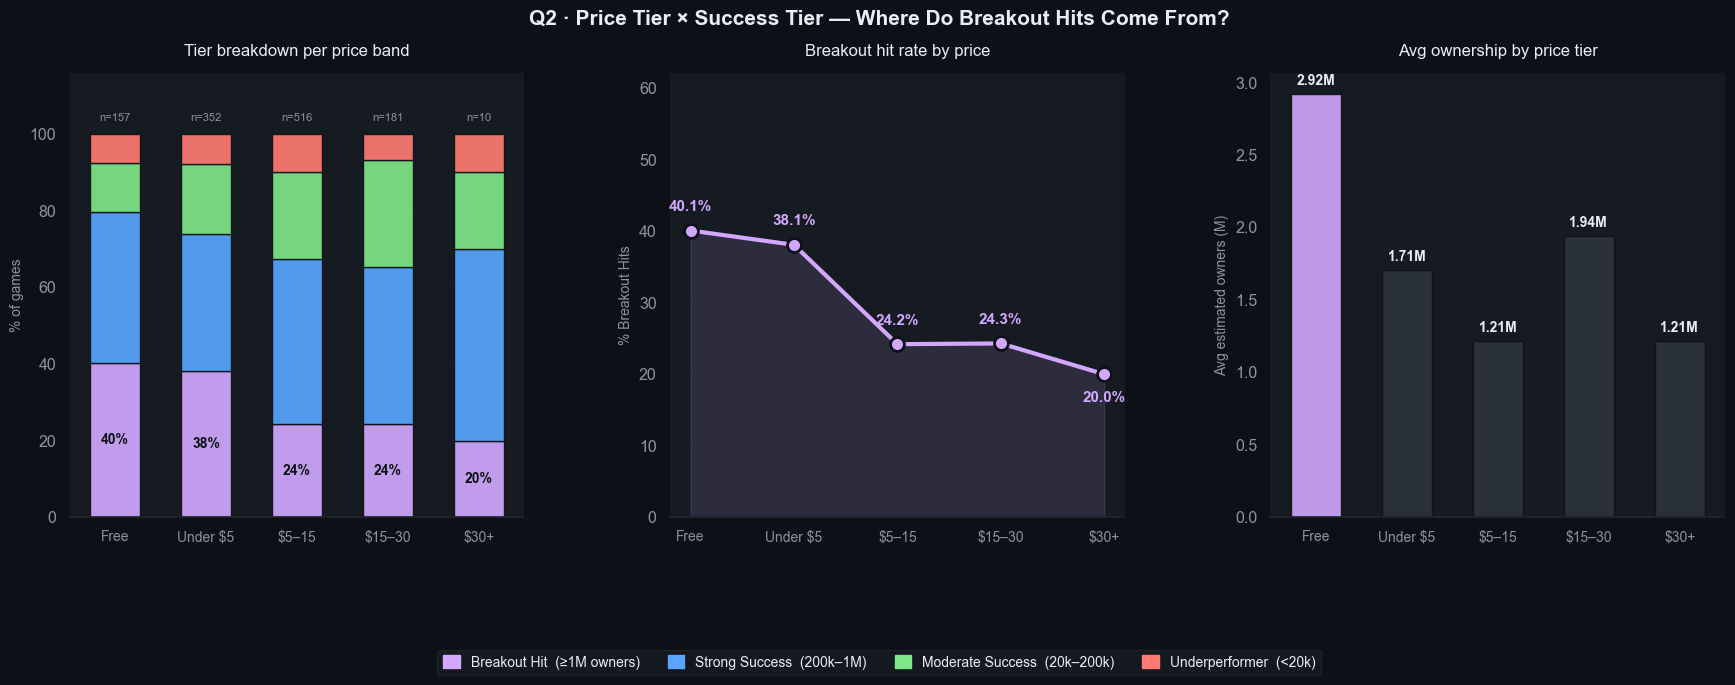

In [35]:
# ── Q2 Chart: Price Tier × Success Tier breakdown (revised) ──────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG      = '#0D1117'
CARD    = '#161B22'
GRID    = '#21262D'
TEXT    = '#E6EDF3'
SUBTEXT = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': TEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

# ── Prep ──────────────────────────────────────────────────────────────────────
price_order = ['free', 'under_5', '5_to_15', '15_to_30', 'premium_30+']
tier_label_map = {
    'free': 'Free', 'under_5': 'Under $5',
    '5_to_15': '$5–15', '15_to_30': '$15–30', 'premium_30+': '$30+'
}

q2_plot = q2[q2['price_tier'].isin(price_order)].copy()
q2_plot['price_tier'] = pd.Categorical(q2_plot['price_tier'], categories=price_order, ordered=True)
q2_plot = q2_plot.sort_values('price_tier')
q2_plot['label'] = q2_plot['price_tier'].map(tier_label_map)

labels    = q2_plot['label'].tolist()
totals    = q2_plot['total_games'].values
breakouts = q2_plot['breakout_hits'].values
strongs   = q2_plot['strong_successes'].values
moderates = q2_plot['moderate_successes'].values
unders    = q2_plot['underperformers'].values
pct_b     = q2_plot['pct_breakout'].values
avg_own   = q2_plot['avg_owners'].values / 1e6

pct_break  = breakouts  / totals * 100
pct_strong = strongs    / totals * 100
pct_mod    = moderates  / totals * 100
pct_under  = unders     / totals * 100

x = np.arange(len(labels))
W = 0.55

# ── Layout: title row + 3 panels + legend row ─────────────────────────────────
fig = plt.figure(figsize=(18, 7), facecolor=BG)

# Leave room at bottom for legend
gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.07], hspace=0.18, wspace=0.32,
                      left=0.05, right=0.97, top=0.88, bottom=0.14)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])

fig.suptitle('Q2 · Price Tier × Success Tier — Where Do Breakout Hits Come From?',
             fontsize=15, fontweight='700', color=TEXT, y=0.97)

def clean_ax(ax):
    ax.set_facecolor(CARD)
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(axis='both', colors=SUBTEXT)

# ── Panel 1: Stacked bar ──────────────────────────────────────────────────────
b1 = ax1.bar(x, pct_break,  width=W, color=C_BREAKOUT,  alpha=0.92, edgecolor=BG, label='Breakout Hit')
b2 = ax1.bar(x, pct_strong, width=W, bottom=pct_break,  color=C_STRONG,   alpha=0.92, edgecolor=BG, label='Strong Success')
b3 = ax1.bar(x, pct_mod,    width=W, bottom=pct_break+pct_strong,          color=C_MODERATE, alpha=0.92, edgecolor=BG, label='Moderate Success')
b4 = ax1.bar(x, pct_under,  width=W, bottom=pct_break+pct_strong+pct_mod,  color=C_UNDER,    alpha=0.92, edgecolor=BG, label='Underperformer')

# Annotate breakout % inside bar, only if segment tall enough
for i, pb in enumerate(pct_break):
    if pb > 8:
        ax1.text(i, pb / 2, f'{pb:.0f}%', ha='center', va='center',
                 fontsize=10, fontweight='bold', color=BG)

# n= totals above bars
for i, tot in enumerate(totals):
    ax1.text(i, 103, f'n={tot}', ha='center', va='bottom', fontsize=8, color=SUBTEXT)

ax1.set_xticks(x); ax1.set_xticklabels(labels, fontsize=10)
ax1.set_ylabel('% of games', color=SUBTEXT, fontsize=10)
ax1.set_title('Tier breakdown per price band', fontsize=12, color=TEXT, pad=12)
ax1.set_ylim(0, 116)
ax1.grid(True, axis='y', alpha=0.15)
clean_ax(ax1)

# ── Panel 2: Breakout rate line ───────────────────────────────────────────────
ax2.plot(x, pct_b, color=C_BREAKOUT, linewidth=3, marker='o', markersize=10,
         markerfacecolor=C_BREAKOUT, markeredgecolor=BG, markeredgewidth=2, zorder=5)
ax2.fill_between(x, pct_b, alpha=0.12, color=C_BREAKOUT)

for i, v in enumerate(pct_b):
    offset = 14 if i != len(pct_b)-1 else -20
    ax2.annotate(f'{v:.1f}%', (i, v), textcoords='offset points',
                 xytext=(0, offset), ha='center', fontsize=11,
                 fontweight='bold', color=C_BREAKOUT)

ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('% Breakout Hits', color=SUBTEXT, fontsize=10)
ax2.set_title('Breakout hit rate by price', fontsize=12, color=TEXT, pad=12)
ax2.set_ylim(0, max(pct_b) * 1.55)
ax2.grid(True, axis='y', alpha=0.15)
clean_ax(ax2)

# ── Panel 3: Avg owners ───────────────────────────────────────────────────────
max_idx = np.argmax(avg_own)
bar_colors = [C_BREAKOUT if i == max_idx else '#2D333B' for i in range(len(avg_own))]
bars = ax3.bar(x, avg_own, color=bar_colors, alpha=0.9, edgecolor=BG, width=W)

for bar, val in zip(bars, avg_own):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.04,
             f'{val:.2f}M', ha='center', va='bottom',
             fontsize=10, fontweight='bold', color=TEXT)

ax3.set_xticks(x); ax3.set_xticklabels(labels, fontsize=10)
ax3.set_ylabel('Avg estimated owners (M)', color=SUBTEXT, fontsize=10)
ax3.set_title('Avg ownership by price tier', fontsize=12, color=TEXT, pad=12)
ax3.grid(True, axis='y', alpha=0.15)
clean_ax(ax3)

# ── Legend: single row below all panels ──────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=C_BREAKOUT,  label='Breakout Hit  (≥1M owners)'),
    mpatches.Patch(color=C_STRONG,    label='Strong Success  (200k–1M)'),
    mpatches.Patch(color=C_MODERATE,  label='Moderate Success  (20k–200k)'),
    mpatches.Patch(color=C_UNDER,     label='Underperformer  (<20k)'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=4,
           fontsize=10, frameon=True, facecolor=CARD, edgecolor=GRID,
           bbox_to_anchor=(0.5, 0.01), handlelength=1.2, handleheight=1.0,
           columnspacing=2.0)

plt.show()

placeholder

In [10]:
# Q3: Platform count (from IGDB) vs success tier.
# Breaks down the four success tiers by number of platforms available,
# allowing us to see if Breakout Hits disproportionately appear on more platforms.

q3 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT num_platforms, COUNT(*) AS num_games,
        SUM(CASE WHEN success_tier='Breakout Hit'     THEN 1 ELSE 0 END) AS breakout_hits,
        SUM(CASE WHEN success_tier='Strong Success'   THEN 1 ELSE 0 END) AS strong_successes,
        SUM(CASE WHEN success_tier='Moderate Success' THEN 1 ELSE 0 END) AS moderate_successes,
        SUM(CASE WHEN success_tier='Underperformer'   THEN 1 ELSE 0 END) AS underperformers,
        ROUND(AVG(igdb_critic_score), 1)              AS avg_critic_score,
        ROUND(AVG(owners_estimate), 0)                AS avg_owners,
        ROUND(AVG(peak_ccu), 0)                       AS avg_peak_ccu
    FROM tiered WHERE num_platforms IS NOT NULL
    GROUP BY num_platforms ORDER BY num_platforms
""").df()
display(q3)


,num_platforms,num_games,breakout_hits,strong_successes,moderate_successes,underperformers,avg_critic_score,avg_owners,avg_peak_ccu
0,0.0,8,3.0,4.0,1.0,0.0,NaN,1141875.0,236.0
1,1.0,421,79.0,173.0,120.0,49.0,79.5,996188.0,1030.0
2,2.0,122,28.0,48.0,32.0,14.0,79.1,1143852.0,1801.0
3,3.0,204,64.0,80.0,42.0,18.0,76.1,1488995.0,1141.0
4,4.0,91,25.0,44.0,17.0,5.0,74.2,1905769.0,1338.0
5,5.0,89,40.0,35.0,13.0,1.0,79.8,2632135.0,1192.0
6,6.0,90,42.0,42.0,5.0,1.0,79.9,2551889.0,1362.0
7,7.0,48,24.0,17.0,6.0,1.0,79.7,3025938.0,1572.0
8,8.0,41,24.0,14.0,3.0,0.0,81.0,2137805.0,754.0
9,9.0,20,8.0,10.0,2.0,0.0,82.2,1890000.0,698.0


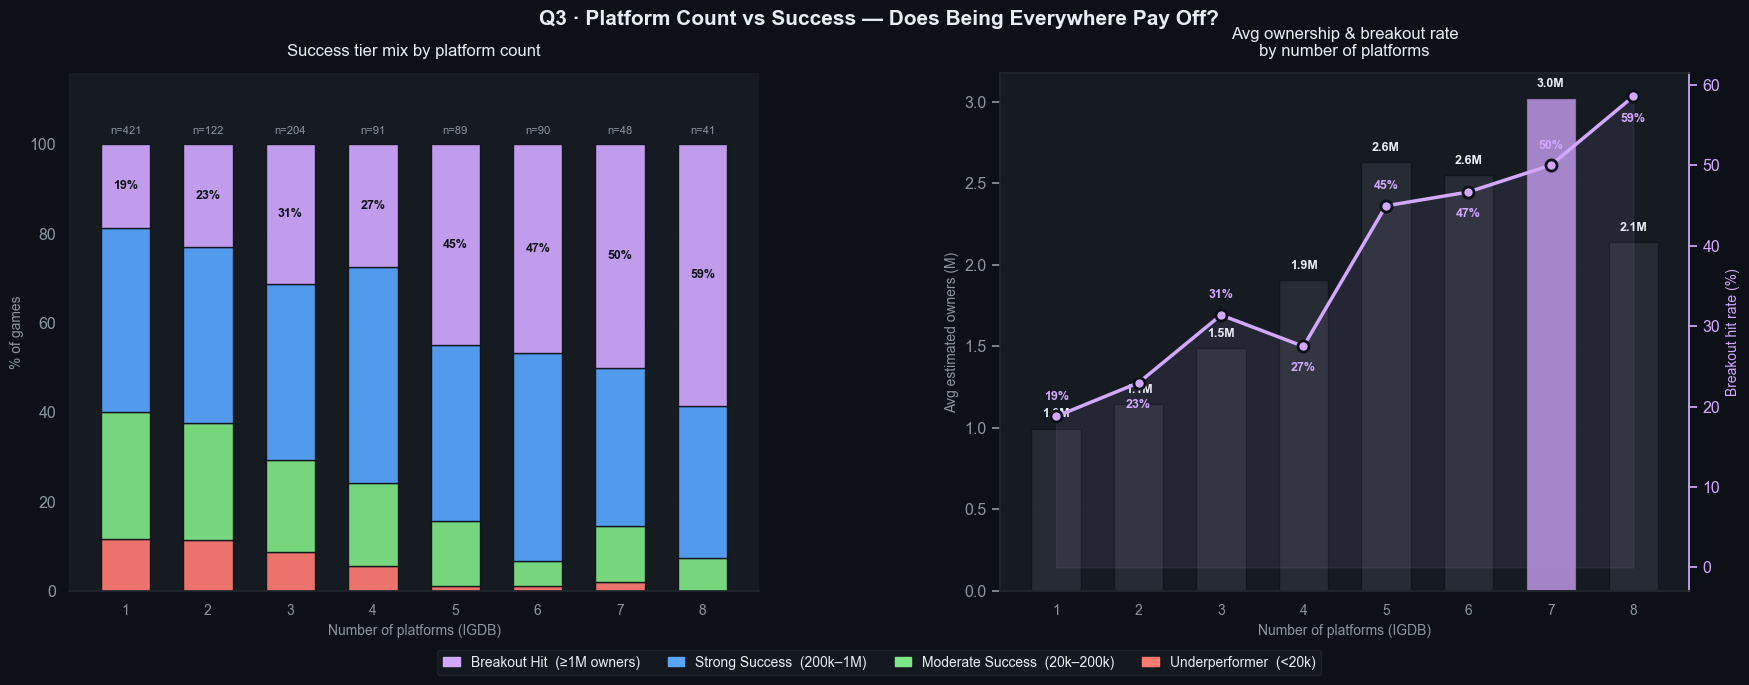

In [37]:
# ── Q3 Chart: Platform Count × Success Tier (v3) ─────────────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': TEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax):
    ax.set_facecolor(CARD)
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

# ── Prep ──────────────────────────────────────────────────────────────────────
# Only keep platform counts with enough games AND cap at 8 to avoid sparse noise
q3_plot = q3[(q3['num_games'] >= 10) & (q3['num_platforms'] <= 8)].copy()
q3_plot = q3_plot.sort_values('num_platforms')

plat     = q3_plot['num_platforms'].astype(int).tolist()
totals   = q3_plot['num_games'].values
avg_own  = q3_plot['avg_owners'].values / 1e6
avg_crit = q3_plot['avg_critic_score'].fillna(0).values

pct_break  = q3_plot['breakout_hits'].values    / totals * 100
pct_strong = q3_plot['strong_successes'].values / totals * 100
pct_mod    = q3_plot['moderate_successes'].values / totals * 100
pct_under  = q3_plot['underperformers'].values  / totals * 100

x     = np.arange(len(plat))
xlabs = [str(p) for p in plat]
W     = 0.6

# ── Figure ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 7), facecolor=BG)
gs  = fig.add_gridspec(1, 2, wspace=0.35, left=0.05, right=0.95, top=0.88, bottom=0.14)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

fig.suptitle('Q3 · Platform Count vs Success — Does Being Everywhere Pay Off?',
             fontsize=15, fontweight='700', color=TEXT, y=0.97)

# ── Panel 1: Stacked % bars ───────────────────────────────────────────────────
# Stack order: Underperformer at bottom → Breakout at top (worst → best)
b_under = ax1.bar(x, pct_under,  width=W, color=C_UNDER,    alpha=0.92, edgecolor=BG)
b_mod   = ax1.bar(x, pct_mod,    width=W, bottom=pct_under, color=C_MODERATE, alpha=0.92, edgecolor=BG)
b_str   = ax1.bar(x, pct_strong, width=W, bottom=pct_under+pct_mod, color=C_STRONG, alpha=0.92, edgecolor=BG)
b_brk   = ax1.bar(x, pct_break,  width=W, bottom=pct_under+pct_mod+pct_strong, color=C_BREAKOUT, alpha=0.92, edgecolor=BG)

# Annotate breakout % inside the top (purple) segment
for i, (pb, pu, pm, ps) in enumerate(zip(pct_break, pct_under, pct_mod, pct_strong)):
    base = pu + pm + ps
    if pb > 7:
        ax1.text(i, base + pb / 2, f'{pb:.0f}%',
                 ha='center', va='center', fontsize=9, fontweight='bold', color=BG)
    ax1.text(i, 102, f'n={totals[i]}', ha='center', va='bottom', fontsize=8, color=SUBTEXT)

ax1.set_xticks(x)
ax1.set_xticklabels(xlabs, fontsize=10)
ax1.set_xlabel('Number of platforms (IGDB)', color=SUBTEXT, fontsize=10)
ax1.set_ylabel('% of games', color=SUBTEXT, fontsize=10)
ax1.set_title('Success tier mix by platform count', fontsize=12, color=TEXT, pad=12)
ax1.set_ylim(0, 116)
ax1.grid(True, axis='y', alpha=0.15)
clean_ax(ax1)

# ── Panel 2: Clean line chart — platforms vs avg ownership + breakout % ───────
ax2b = ax2.twinx()

# Bars: avg ownership
bar_cols = [C_BREAKOUT if o == avg_own.max() else '#2D333B' for o in avg_own]
ax2.bar(x, avg_own, width=W, color=bar_cols, alpha=0.75, edgecolor=BG, zorder=2)

# Line: breakout hit rate
ax2b.plot(x, pct_break, color=C_BREAKOUT, linewidth=2.5, marker='o', markersize=8,
          markerfacecolor=C_BREAKOUT, markeredgecolor=BG, markeredgewidth=2, zorder=5)
ax2b.fill_between(x, pct_break, alpha=0.08, color=C_BREAKOUT)

# Annotate ownership on bars
for i, v in enumerate(avg_own):
    ax2.text(i, v + 0.05, f'{v:.1f}M', ha='center', va='bottom',
             fontsize=9, fontweight='bold', color=TEXT)

# Annotate breakout % on line (alternate up/down to avoid overlap)
for i, v in enumerate(pct_break):
    offset = 12 if i % 2 == 0 else -18
    ax2b.annotate(f'{v:.0f}%', (i, v), textcoords='offset points',
                  xytext=(0, offset), ha='center', fontsize=9,
                  fontweight='bold', color=C_BREAKOUT)

ax2.set_xticks(x)
ax2.set_xticklabels(xlabs, fontsize=10)
ax2.set_xlabel('Number of platforms (IGDB)', color=SUBTEXT, fontsize=10)
ax2.set_ylabel('Avg estimated owners (M)', color=SUBTEXT, fontsize=10)
ax2b.set_ylabel('Breakout hit rate (%)', color=C_BREAKOUT, fontsize=10)
ax2b.tick_params(axis='y', colors=C_BREAKOUT)
ax2b.spines['right'].set_edgecolor(C_BREAKOUT)
ax2.set_title('Avg ownership & breakout rate\nby number of platforms', fontsize=12, color=TEXT, pad=12)
ax2.grid(True, axis='y', alpha=0.15)
clean_ax(ax2)
ax2.spines['right'].set_visible(True)
ax2.spines['right'].set_edgecolor(GRID)

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=C_BREAKOUT,  label='Breakout Hit  (≥1M owners)'),
    mpatches.Patch(color=C_STRONG,    label='Strong Success  (200k–1M)'),
    mpatches.Patch(color=C_MODERATE,  label='Moderate Success  (20k–200k)'),
    mpatches.Patch(color=C_UNDER,     label='Underperformer  (<20k)'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=4,
           fontsize=10, frameon=True, facecolor=CARD, edgecolor=GRID,
           bbox_to_anchor=(0.5, 0.01), handlelength=1.2, columnspacing=2.0)

plt.show()

In [12]:
print(df['avg_vader_compound'].notna().sum(), "games have VADER scores")
print(df['avg_vader_compound'].head(10))

1212 games have VADER scores
0    0.592737
1    0.554533
2    0.409952
3    0.590277
4    0.274556
5    0.580880
6    0.366454
7    0.226643
8    0.437831
9    0.198011
Name: avg_vader_compound, dtype: float64


placeholder

In [13]:
# Q4: VADER review sentiment vs success tier.
# Shows whether review sentiment separates the four tiers — particularly whether
# Breakout Hits attract qualitatively different language than Moderate Successes.
# avg_vader_compound is the mean VADER compound score across all English Steam reviews
# for each game, computed by the Spark pipeline UDF.

q4 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT success_tier, tier_rank,
        COUNT(*) AS num_games,
        ROUND(AVG(avg_vader_compound), 4)        AS avg_vader_score,
        ROUND(AVG(pct_positive_reviews), 1)      AS avg_pct_positive,
        ROUND(AVG(avg_playtime_at_review), 0)    AS avg_playtime_at_review_mins,
        ROUND(AVG(num_reviews_analysed), 0)      AS avg_reviews_per_game,
        ROUND(AVG(owners_estimate), 0)           AS avg_owners
    FROM tiered
    WHERE avg_vader_compound IS NOT NULL
    GROUP BY success_tier, tier_rank
    ORDER BY tier_rank
""").df()
display(q4)


,success_tier,tier_rank,num_games,avg_vader_score,avg_pct_positive,avg_playtime_at_review_mins,avg_reviews_per_game,avg_owners
0,Breakout Hit,1,368,0.4290,83.2,7490.0,74.0,4769022.0
1,Strong Success,2,490,0.4147,81.2,5721.0,45.0,547551.0
2,Moderate Success,3,254,0.4525,81.2,4295.0,27.0,101811.0
3,Underperformer,4,100,0.4385,81.4,3950.0,17.0,10000.0


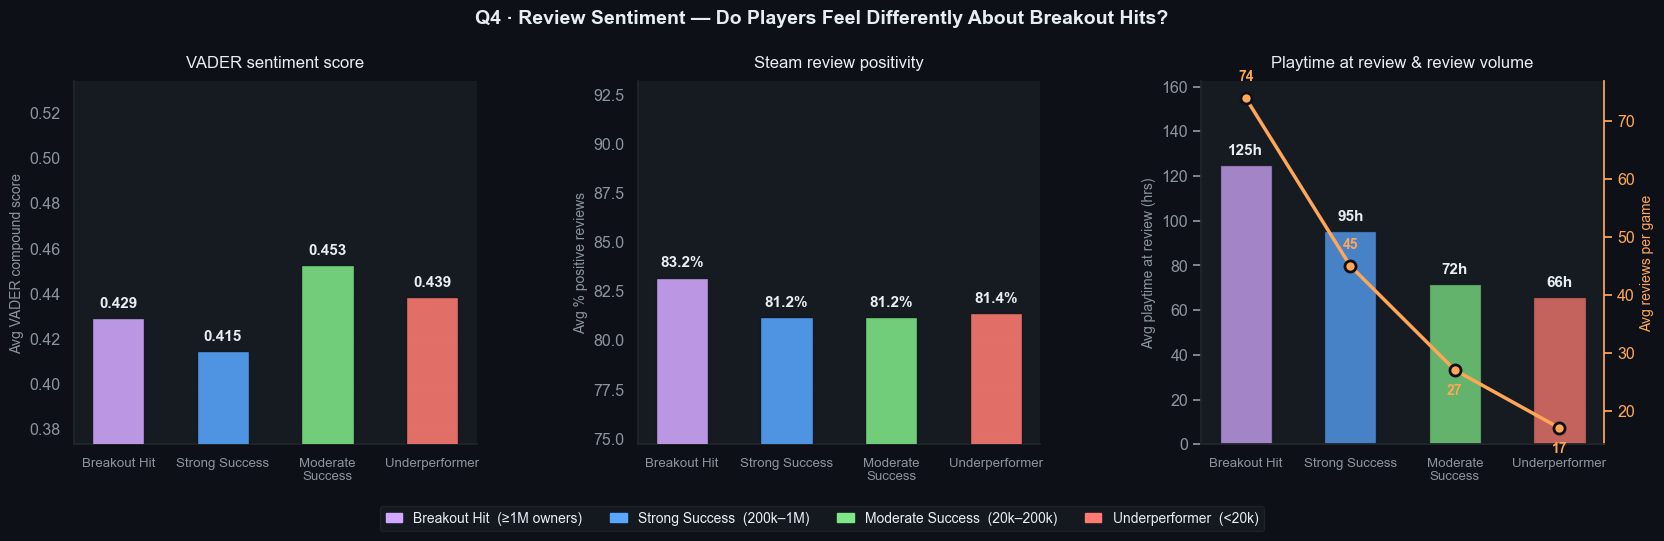

In [39]:
# ── Q4 Chart: VADER Sentiment × Success Tier (v2) ────────────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'
TIER_COLORS = [C_BREAKOUT, C_STRONG, C_MODERATE, C_UNDER]

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax, keep_left=True):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(keep_left)
    ax.spines['bottom'].set_edgecolor(GRID)
    if keep_left:
        ax.spines['left'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

# ── Prep ──────────────────────────────────────────────────────────────────────
tier_order   = ['Breakout Hit', 'Strong Success', 'Moderate Success', 'Underperformer']
short_labels = ['Breakout Hit', 'Strong Success', 'Moderate\nSuccess', 'Underperformer']

q4_plot     = q4.set_index('success_tier').reindex(tier_order).reset_index()
vader       = q4_plot['avg_vader_score'].values.astype(float)
pct_pos     = q4_plot['avg_pct_positive'].values.astype(float)
playtime    = q4_plot['avg_playtime_at_review_mins'].values.astype(float)
n_reviews   = q4_plot['avg_reviews_per_game'].values.astype(float)

x = np.arange(4)
W = 0.5

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), facecolor=BG)
fig.subplots_adjust(left=0.06, right=0.96, top=0.84, bottom=0.18, wspace=0.4)

fig.suptitle('Q4 · Review Sentiment — Do Players Feel Differently About Breakout Hits?',
             fontsize=14, fontweight='700', color=TEXT, y=0.97)

# ── Panel 1: VADER score ──────────────────────────────────────────────────────
ax = axes[0]
bars = ax.bar(x, vader, width=W, color=TIER_COLORS, alpha=0.88, edgecolor=BG, zorder=3)
ax.axhline(0, color=SUBTEXT, linewidth=1, linestyle='--', alpha=0.4, zorder=2)

vmin = min(vader) * 0.9
vmax = max(vader) * 1.18
ax.set_ylim(vmin, vmax)

for bar, val in zip(bars, vader):
    ax.text(bar.get_x() + bar.get_width()/2, val + (vmax - vmin) * 0.02,
            f'{val:.3f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=TEXT)

ax.set_xticks(x)
ax.set_xticklabels(short_labels, fontsize=9.5)
ax.set_ylabel('Avg VADER compound score', fontsize=10)
ax.set_title('VADER sentiment score', fontsize=12, color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15, zorder=0)
clean_ax(ax)

# ── Panel 2: % Positive reviews ───────────────────────────────────────────────
ax = axes[1]
bars2 = ax.bar(x, pct_pos, width=W, color=TIER_COLORS, alpha=0.88, edgecolor=BG, zorder=3)

pmin = min(pct_pos) * 0.92
pmax = max(pct_pos) * 1.12
ax.set_ylim(pmin, pmax)

for bar, val in zip(bars2, pct_pos):
    ax.text(bar.get_x() + bar.get_width()/2, val + (pmax - pmin) * 0.02,
            f'{val:.1f}%', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=TEXT)

ax.set_xticks(x)
ax.set_xticklabels(short_labels, fontsize=9.5)
ax.set_ylabel('Avg % positive reviews', fontsize=10)
ax.set_title('Steam review positivity', fontsize=12, color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15, zorder=0)
clean_ax(ax)

# ── Panel 3: Playtime at review (hrs) + review volume line ───────────────────
ax  = axes[2]
ax2 = ax.twinx()

playtime_hrs = playtime / 60
bars3 = ax.bar(x, playtime_hrs, width=W, color=TIER_COLORS, alpha=0.75, edgecolor=BG, zorder=3)

tmin = 0
tmax = max(playtime_hrs) * 1.3
ax.set_ylim(tmin, tmax)

for bar, val in zip(bars3, playtime_hrs):
    ax.text(bar.get_x() + bar.get_width()/2, val + tmax * 0.02,
            f'{val:.0f}h', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=TEXT)

ax2.plot(x, n_reviews, color='#FFA657', linewidth=2.5, marker='o', markersize=8,
         markerfacecolor='#FFA657', markeredgecolor=BG, markeredgewidth=2, zorder=5)

for i, val in enumerate(n_reviews):
    offset = 12 if i < 2 else -18
    ax2.annotate(f'{int(val)}', (i, val), textcoords='offset points',
                 xytext=(0, offset), ha='center', fontsize=10,
                 fontweight='bold', color='#FFA657')

ax.set_xticks(x)
ax.set_xticklabels(short_labels, fontsize=9.5)
ax.set_ylabel('Avg playtime at review (hrs)', fontsize=10)
ax2.set_ylabel('Avg reviews per game', color='#FFA657', fontsize=10)
ax2.tick_params(axis='y', colors='#FFA657')
ax2.spines['right'].set_edgecolor('#FFA657')
ax2.spines['top'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax.set_title('Playtime at review & review volume', fontsize=12, color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15, zorder=0)
clean_ax(ax)
ax.spines['right'].set_visible(True)
ax.spines['right'].set_edgecolor(GRID)

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=C_BREAKOUT, label='Breakout Hit  (≥1M owners)'),
    mpatches.Patch(color=C_STRONG,   label='Strong Success  (200k–1M)'),
    mpatches.Patch(color=C_MODERATE, label='Moderate Success  (20k–200k)'),
    mpatches.Patch(color=C_UNDER,    label='Underperformer  (<20k)'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=4,
           fontsize=10, frameon=True, facecolor=CARD, edgecolor=GRID,
           bbox_to_anchor=(0.5, 0.01), handlelength=1.2, columnspacing=2.0)

plt.show()

placeholder

In [15]:
# Q5: Dedicated subreddit presence vs success tier.
# A 4-tier breakdown shows whether the community-building effect is gradual
# (Moderate Success → Strong Success → Breakout Hit) or a binary jump.
# has_dedicated_subreddit was computed from Reddit JSON endpoint data.

q5 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT success_tier, tier_rank,
        CAST(has_dedicated_subreddit AS VARCHAR) AS has_subreddit,
        COUNT(*) AS num_games,
        ROUND(AVG(subreddit_subscribers), 0)  AS avg_subscribers,
        ROUND(AVG(total_reddit_posts), 0)     AS avg_posts,
        ROUND(AVG(reddit_engagement), 1)      AS avg_engagement,
        ROUND(AVG(owners_estimate), 0)        AS avg_owners
    FROM tiered
    GROUP BY success_tier, tier_rank, has_dedicated_subreddit
    ORDER BY tier_rank, has_dedicated_subreddit DESC
""").df()
display(q5)


,success_tier,tier_rank,has_subreddit,num_games,avg_subscribers,avg_posts,avg_engagement,avg_owners
0,Breakout Hit,1,true,280,97599.0,49.0,1727092.9,5350000.0
1,Breakout Hit,1,false,88,NaN,47.0,1117135.4,2920455.0
2,Strong Success,2,true,303,8100.0,48.0,1169413.3,562541.0
3,Strong Success,2,false,187,NaN,43.0,1441523.4,523262.0
4,Moderate Success,3,true,118,2561.0,48.0,1048253.0,104449.0
5,Moderate Success,3,false,137,NaN,39.0,884266.4,99891.0
6,Underperformer,4,true,25,7829.0,45.0,724093.7,10000.0
7,Underperformer,4,false,78,NaN,38.0,1301657.3,10000.0


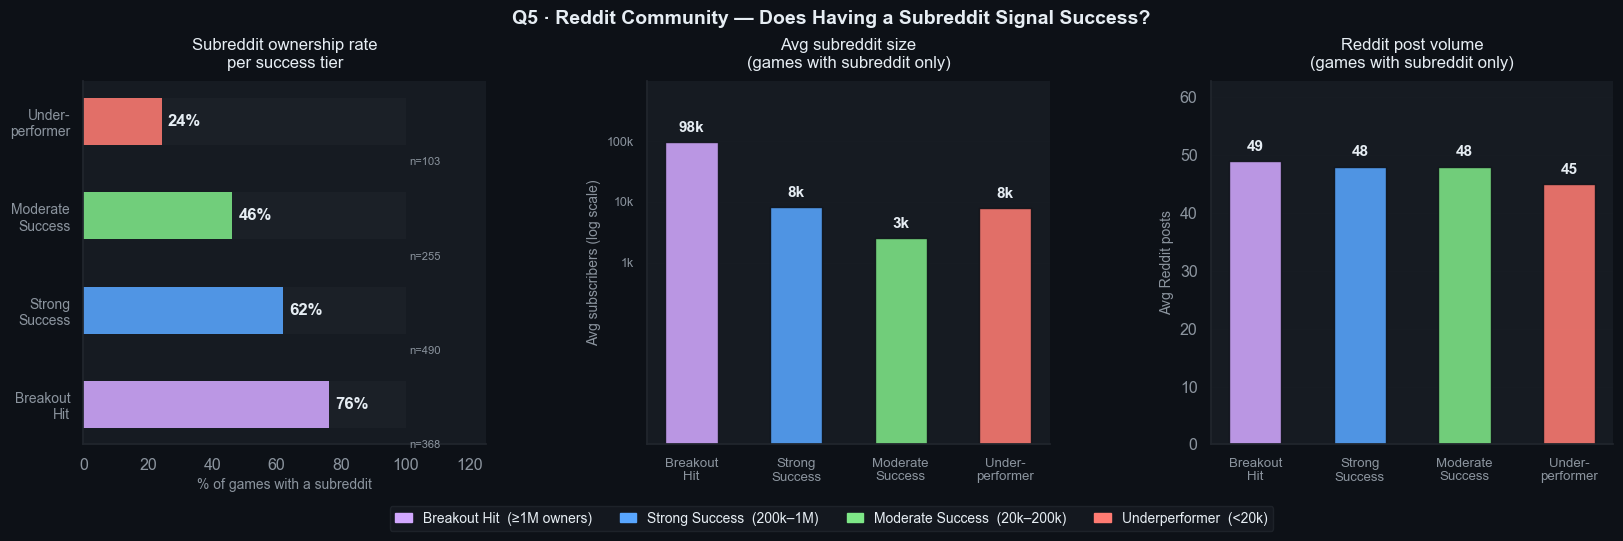

In [41]:
# ── Q5 Chart: Subreddit Presence × Success Tier (v3) ─────────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'
TIER_COLORS = [C_BREAKOUT, C_STRONG, C_MODERATE, C_UNDER]

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_edgecolor(GRID)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

# ── Prep ──────────────────────────────────────────────────────────────────────
tier_order   = ['Breakout Hit', 'Strong Success', 'Moderate Success', 'Underperformer']
short_labels = ['Breakout\nHit', 'Strong\nSuccess', 'Moderate\nSuccess', 'Under-\nperformer']

has_sub = q5[q5['has_subreddit'] == 'true'].set_index('success_tier').reindex(tier_order)
no_sub  = q5[q5['has_subreddit'] == 'false'].set_index('success_tier').reindex(tier_order)

total_per_tier = has_sub['num_games'].fillna(0).values + no_sub['num_games'].fillna(0).values
pct_has_sub    = has_sub['num_games'].fillna(0).values / total_per_tier * 100

# Subscribers: log scale to handle Breakout Hit dominance
avg_subs_raw = has_sub['avg_subscribers'].fillna(0).values
avg_posts    = has_sub['avg_posts'].fillna(0).values

x = np.arange(4)
W = 0.5

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), facecolor=BG)
fig.subplots_adjust(left=0.06, right=0.96, top=0.84, bottom=0.18, wspace=0.4)

fig.suptitle('Q5 · Reddit Community — Does Having a Subreddit Signal Success?',
             fontsize=14, fontweight='700', color=TEXT, y=0.97)

# ── Panel 1: % with subreddit — dot + bar combo ───────────────────────────────
ax = axes[0]

# Background 100% track
ax.barh(x, [100]*4, height=W, color=GRID, alpha=0.5, edgecolor='none')
# Filled portion = has subreddit
bars = ax.barh(x, pct_has_sub, height=W, color=TIER_COLORS, alpha=0.88, edgecolor='none')

for i, (pct, tot) in enumerate(zip(pct_has_sub, total_per_tier)):
    ax.text(pct + 2, i, f'{pct:.0f}%', va='center', fontsize=12,
            fontweight='bold', color=TEXT)
    ax.text(101, i - 0.38, f'n={int(tot)}', va='top', fontsize=8, color=SUBTEXT)

ax.set_yticks(x)
ax.set_yticklabels(short_labels, fontsize=10, color=TEXT)
ax.set_xlim(0, 125)
ax.set_xlabel('% of games with a subreddit', fontsize=10)
ax.set_title('Subreddit ownership rate\nper success tier', fontsize=12, color=TEXT, pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_edgecolor(GRID)
ax.spines['bottom'].set_edgecolor(GRID)
ax.set_facecolor(CARD)
ax.tick_params(colors=SUBTEXT)
ax.grid(False)

# ── Panel 2: Subscribers on log scale ────────────────────────────────────────
ax = axes[1]
log_subs = np.log10(np.clip(avg_subs_raw, 1, None))
bars2 = ax.bar(x, log_subs, width=W, color=TIER_COLORS, alpha=0.88, edgecolor=BG)

lmax = max(log_subs) * 1.2
ax.set_ylim(0, lmax)

for bar, raw, lv in zip(bars2, avg_subs_raw, log_subs):
    # Format raw value nicely
    if raw >= 1000:
        label = f'{raw/1000:.0f}k'
    else:
        label = f'{int(raw)}'
    ax.text(bar.get_x() + bar.get_width()/2, lv + lmax * 0.02,
            label, ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=TEXT)

# Custom y-ticks showing actual values
tick_vals = [3, 4, 5]
ax.set_yticks(tick_vals)
ax.set_yticklabels(['1k', '10k', '100k'], fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9.5)
ax.set_ylabel('Avg subscribers (log scale)', fontsize=10)
ax.set_title('Avg subreddit size\n(games with subreddit only)', fontsize=12, color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15)
clean_ax(ax)

# ── Panel 3: Avg Reddit posts per tier ───────────────────────────────────────
ax = axes[2]
bars3 = ax.bar(x, avg_posts, width=W, color=TIER_COLORS, alpha=0.88, edgecolor=BG)

pmax = max(avg_posts) * 1.28
ax.set_ylim(0, pmax)

for bar, val in zip(bars3, avg_posts):
    ax.text(bar.get_x() + bar.get_width()/2, val + pmax * 0.02,
            f'{int(val)}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=TEXT)

ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9.5)
ax.set_ylabel('Avg Reddit posts', fontsize=10)
ax.set_title('Reddit post volume\n(games with subreddit only)', fontsize=12, color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15)
clean_ax(ax)

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=C_BREAKOUT, label='Breakout Hit  (≥1M owners)'),
    mpatches.Patch(color=C_STRONG,   label='Strong Success  (200k–1M)'),
    mpatches.Patch(color=C_MODERATE, label='Moderate Success  (20k–200k)'),
    mpatches.Patch(color=C_UNDER,    label='Underperformer  (<20k)'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=4,
           fontsize=10, frameon=True, facecolor=CARD, edgecolor=GRID,
           bbox_to_anchor=(0.5, 0.01), handlelength=1.2, columnspacing=2.0)

plt.show()

placeholder

In [17]:
# Q6: Google Trends pre/post-launch interest vs success tier.
# Tests whether pre-launch buzz is progressively stronger for higher tiers,
# or whether it only separates Breakout Hits from everyone else.
# google_interest_pre_launch and google_interest_post_launch are engineered
# features computed in spark_pipeline.py from 69,552 weekly search data points.

q6 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT success_tier, tier_rank,
        COUNT(*) AS num_games,
        ROUND(AVG(google_interest_pre_launch), 2)   AS avg_pre_launch_interest,
        ROUND(AVG(google_interest_post_launch), 2)  AS avg_post_launch_interest,
        ROUND(AVG(days_to_peak_interest), 0)        AS avg_days_to_peak,
        COUNT(CASE WHEN trend_direction='rising' THEN 1 END)  AS rising_trends,
        COUNT(CASE WHEN trend_direction='falling' THEN 1 END) AS falling_trends,
        ROUND(AVG(owners_estimate), 0)              AS avg_owners
    FROM tiered
    WHERE google_interest_pre_launch IS NOT NULL
    GROUP BY success_tier, tier_rank
    ORDER BY tier_rank
""").df()
display(q6)


,success_tier,tier_rank,num_games,avg_pre_launch_interest,avg_post_launch_interest,avg_days_to_peak,rising_trends,falling_trends,avg_owners
0,Breakout Hit,1,185,12.44,28.84,162.0,148,20,4070270.0
1,Strong Success,2,324,8.02,26.67,6.0,244,45,537654.0
2,Moderate Success,3,146,8.00,25.22,-206.0,76,20,112671.0
3,Underperformer,4,49,9.61,27.38,-365.0,21,3,10000.0


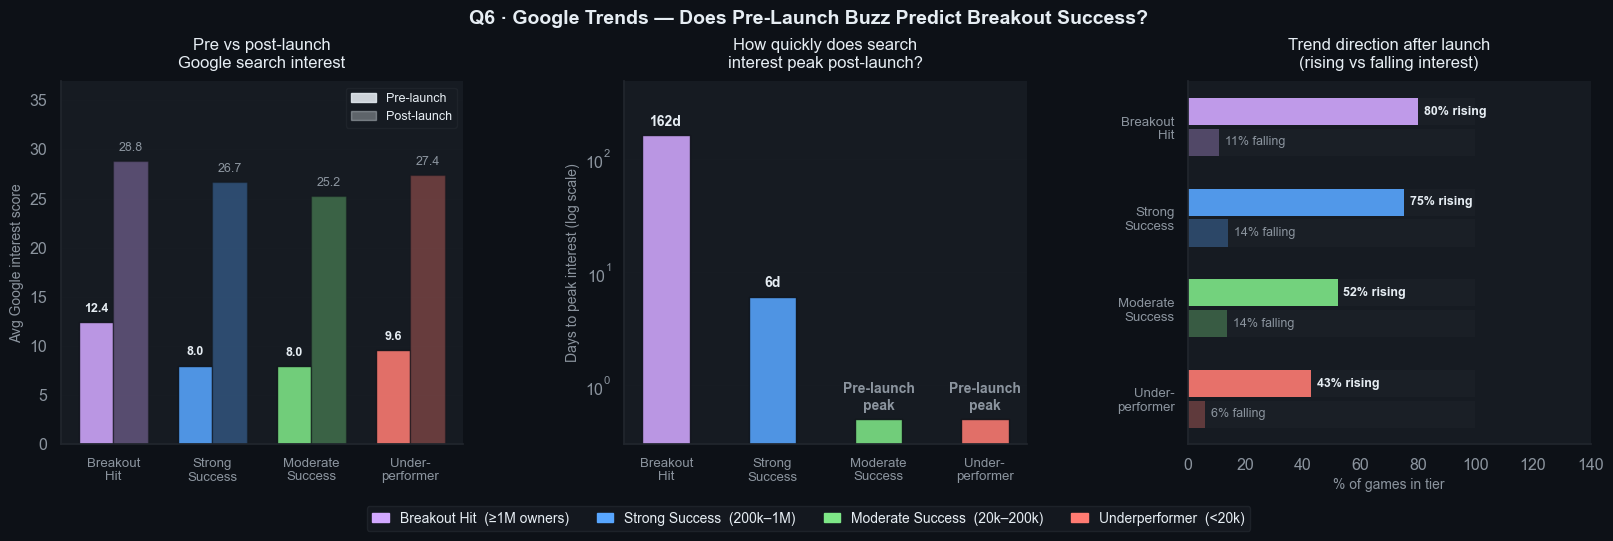

In [42]:
# ── Q6 Chart: Google Trends Pre/Post Launch × Success Tier (v3) ──────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'
TIER_COLORS = [C_BREAKOUT, C_STRONG, C_MODERATE, C_UNDER]

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_edgecolor(GRID)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

# ── Prep ──────────────────────────────────────────────────────────────────────
tier_order   = ['Breakout Hit', 'Strong Success', 'Moderate Success', 'Underperformer']
short_labels = ['Breakout\nHit', 'Strong\nSuccess', 'Moderate\nSuccess', 'Under-\nperformer']

q6_plot   = q6.set_index('success_tier').reindex(tier_order).reset_index()
pre       = q6_plot['avg_pre_launch_interest'].values.astype(float)
post      = q6_plot['avg_post_launch_interest'].values.astype(float)
days_peak = q6_plot['avg_days_to_peak'].values.astype(float)
rising    = q6_plot['rising_trends'].values.astype(float)
falling   = q6_plot['falling_trends'].values.astype(float)
n_games   = q6_plot['num_games'].values.astype(float)
rising_pct  = rising  / n_games * 100
falling_pct = falling / n_games * 100

days_peak_clamped = np.clip(days_peak, 0, None)

x = np.arange(4)
W = 0.35

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), facecolor=BG)
fig.subplots_adjust(left=0.06, right=0.96, top=0.84, bottom=0.18, wspace=0.4)

fig.suptitle('Q6 · Google Trends — Does Pre-Launch Buzz Predict Breakout Success?',
             fontsize=14, fontweight='700', color=TEXT, y=0.97)

# ── Panel 1: Pre vs Post launch interest ─────────────────────────────────────
ax = axes[0]

bars_pre  = ax.bar(x - W/2, pre,  width=W, color=TIER_COLORS, alpha=0.88, edgecolor=BG)
bars_post = ax.bar(x + W/2, post, width=W, color=TIER_COLORS, alpha=0.35, edgecolor=BG)

vmax = max(max(pre), max(post)) * 1.28
ax.set_ylim(0, vmax)

for i, (p1, p2) in enumerate(zip(pre, post)):
    ax.text(i - W/2, p1 + vmax*0.02, f'{p1:.1f}',
            ha='center', va='bottom', fontsize=9, fontweight='bold', color=TEXT)
    ax.text(i + W/2, p2 + vmax*0.02, f'{p2:.1f}',
            ha='center', va='bottom', fontsize=9, color=SUBTEXT)

ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9.5)
ax.set_ylabel('Avg Google interest score', fontsize=10)
ax.set_title('Pre vs post-launch\nGoogle search interest', fontsize=12, color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15)

p1 = mpatches.Patch(color='#E6EDF3', alpha=0.88, label='Pre-launch')
p2 = mpatches.Patch(color='#E6EDF3', alpha=0.35, label='Post-launch')
ax.legend(handles=[p1, p2], fontsize=9, frameon=True,
          facecolor=CARD, edgecolor=GRID, loc='upper right')
clean_ax(ax)

# ── Panel 2: Days to peak – log scale so all tiers are visible ────────────────
ax = axes[1]

# Replace 0 / negative with a small value for log display
days_display = np.where(days_peak_clamped > 0, days_peak_clamped, 0.5)

bars2 = ax.bar(x, days_display, width=W+0.1, color=TIER_COLORS, alpha=0.88, edgecolor=BG)
ax.set_yscale('log')
ax.set_ylim(0.3, max(days_display) * 3)

for i, (bar, raw) in enumerate(zip(bars2, days_peak)):
    if raw < 0:
        label = 'Pre-launch\npeak'
        col = SUBTEXT
    elif raw == 0:
        label = '<1d'
        col = SUBTEXT
    else:
        label = f'{int(raw)}d'
        col = TEXT
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() * 1.15,
            label, ha='center', va='bottom',
            fontsize=10, fontweight='bold', color=col)

ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9.5)
ax.set_ylabel('Days to peak interest (log scale)', fontsize=10)
ax.set_title('How quickly does search\ninterest peak post-launch?', fontsize=12, color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15)
clean_ax(ax)

# ── Panel 3: Rising vs falling ───────────────────────────────────────────────
ax = axes[2]

display_order = list(reversed(range(4)))
bar_h = 0.3
spacing = 1.0
y_positions = [i * spacing for i in range(4)]

for plot_i, tier_i in enumerate(display_order):
    y     = y_positions[plot_i]
    col   = TIER_COLORS[tier_i]
    rp    = rising_pct[tier_i]
    fp    = falling_pct[tier_i]

    ax.barh(y + bar_h/2 + 0.02, 100, height=bar_h, color=GRID, alpha=0.4, edgecolor='none')
    ax.barh(y + bar_h/2 + 0.02, rp,  height=bar_h, color=col,  alpha=0.9, edgecolor='none')
    ax.text(rp + 2, y + bar_h/2 + 0.02, f'{rp:.0f}% rising',
            va='center', fontsize=9, fontweight='bold', color=TEXT)

    ax.barh(y - bar_h/2 - 0.02, 100, height=bar_h, color=GRID, alpha=0.4, edgecolor='none')
    ax.barh(y - bar_h/2 - 0.02, fp,  height=bar_h, color=col,  alpha=0.3, edgecolor='none')
    ax.text(fp + 2, y - bar_h/2 - 0.02, f'{fp:.0f}% falling',
            va='center', fontsize=9, color=SUBTEXT)

ax.set_yticks(y_positions)
ax.set_yticklabels([short_labels[i] for i in display_order], fontsize=9.5, color=TEXT)
ax.set_xlim(0, 140)
ax.set_xlabel('% of games in tier', fontsize=10)
ax.set_title('Trend direction after launch\n(rising vs falling interest)', fontsize=12, color=TEXT, pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_edgecolor(GRID)
ax.spines['bottom'].set_edgecolor(GRID)
ax.set_facecolor(CARD)
ax.tick_params(colors=SUBTEXT)
ax.grid(False)

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=C_BREAKOUT, label='Breakout Hit  (≥1M owners)'),
    mpatches.Patch(color=C_STRONG,   label='Strong Success  (200k–1M)'),
    mpatches.Patch(color=C_MODERATE, label='Moderate Success  (20k–200k)'),
    mpatches.Patch(color=C_UNDER,    label='Underperformer  (<20k)'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=4,
           fontsize=10, frameon=True, facecolor=CARD, edgecolor=GRID,
           bbox_to_anchor=(0.5, 0.01), handlelength=1.2, columnspacing=2.0)

plt.show()

Breakout Hits show the highest pre-launch Google search interest (12.4 vs 8.0 for mid-tiers) and sustain buzz far longer — peaking 162 days after launch compared to just 6 days for Strong Successes. 80% of Breakout Hits maintain a rising trend post-launch, versus only 43% of Underperformers. Pre-launch buzz alone doesn't guarantee success, but sustained, growing interest post-launch is a strong differentiator.placeholder

In [19]:
# Q7: Top 20 breakout hits ranked by peak concurrent users.
# Restricted to games in the Breakout Hit tier (1M+ owners) so the ranking
# is within the elite tier rather than conflating tiers. Includes all key signals.

q7 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT name, success_tier, peak_ccu,
        ROUND(owners_estimate, 0)           AS owners_estimate,
        price,
        ROUND(review_positivity_ratio, 3)   AS review_ratio,
        ROUND(avg_vader_compound, 3)        AS vader_score,
        num_platforms,
        COALESCE(subreddit_subscribers, 0)  AS reddit_subs,
        ROUND(trend_peak, 0)               AS trend_peak
    FROM tiered
    ORDER BY peak_ccu DESC LIMIT 20
""").df()
display(q7)


,name,success_tier,peak_ccu,owners_estimate,price,review_ratio,vader_score,num_platforms,reddit_subs,trend_peak
0,Bongo Cat,Underperformer,164168,10000.0,0.00,NaN,0.612,1.0,12694.0,100
1,Rust,Breakout Hit,143870,35000000.0,19.99,0.872,0.190,2.0,390673.0,100
2,Wallpaper Engine,Breakout Hit,91184,35000000.0,3.99,0.980,0.566,NaN,212778.0,100
3,DELTARUNE,Breakout Hit,83936,1500000.0,19.99,0.989,0.651,6.0,470882.0,100
4,Stardew Valley,Breakout Hit,50662,35000000.0,8.99,0.984,0.812,11.0,3114769.0,100
5,Crosshair X,Breakout Hit,41428,3500000.0,3.49,0.934,0.471,NaN,0.0,100
6,Don't Starve Together,Breakout Hit,30542,15000000.0,5.09,0.953,0.589,4.0,42503.0,100
7,Clicker Cuties - Anime Idler,Underperformer,28258,10000.0,0.00,NaN,0.187,NaN,0.0,0
8,Geometry Dash,Breakout Hit,27850,7500000.0,2.49,0.933,0.460,4.0,646126.0,100
9,Terraria,Breakout Hit,24580,35000000.0,4.99,0.975,0.504,15.0,1590045.0,100


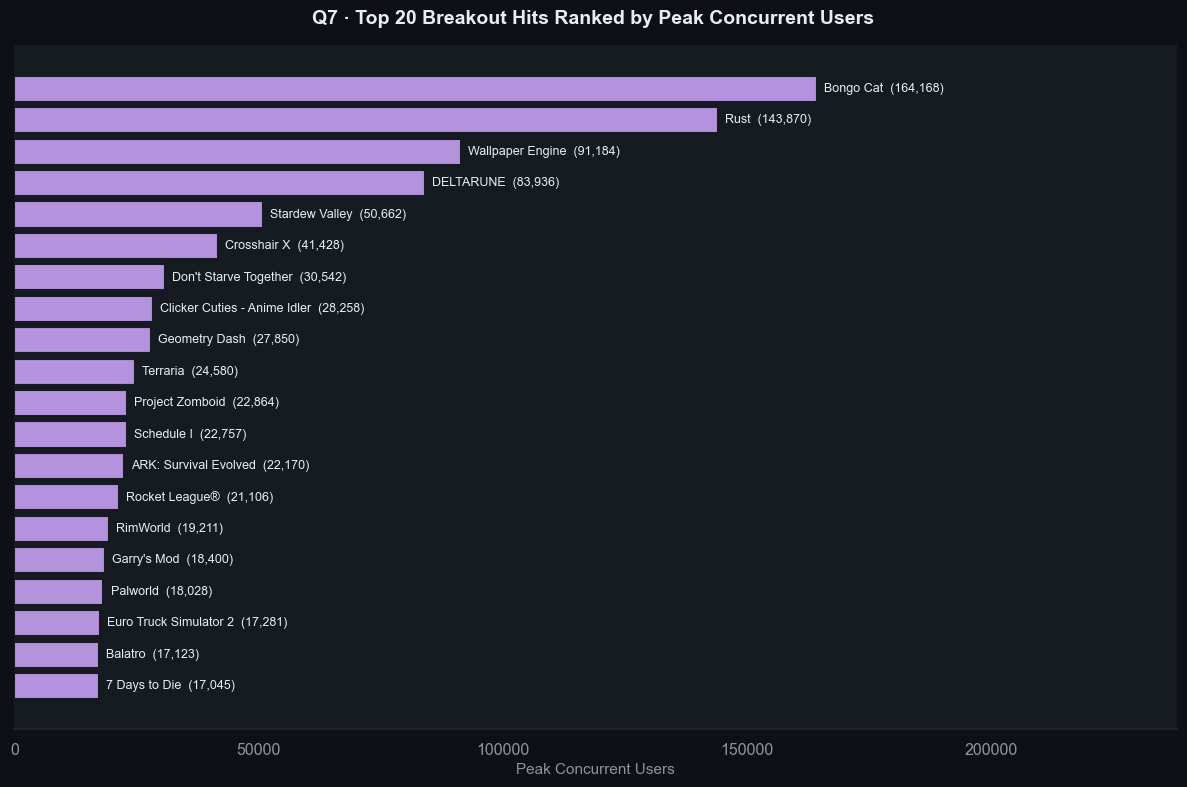

In [20]:
# TODO: Q7 chart
# ── Q7 Chart: Top 20 Breakout Hits by Peak CCU ──────────────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax, keep_left=True):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(keep_left)
    ax.spines['bottom'].set_edgecolor(GRID)
    if keep_left: ax.spines['left'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

q7_plot = q7.sort_values('peak_ccu', ascending=True).tail(20)

fig, ax = plt.subplots(figsize=(12, 8), facecolor=BG)
clean_ax(ax, keep_left=False)

bars = ax.barh(
    range(len(q7_plot)), q7_plot['peak_ccu'].values,
    color=C_BREAKOUT, edgecolor=BG, linewidth=0.8, alpha=0.85
)

for i, (_, row) in enumerate(q7_plot.iterrows()):
    name = row['name'][:30] + '…' if len(str(row['name'])) > 30 else row['name']
    ccu = row['peak_ccu']
    ax.text(ccu + max(q7_plot['peak_ccu']) * 0.01, i, f'{name}  ({ccu:,.0f})',
            va='center', fontsize=9, color=TEXT, fontweight='500')

ax.set_yticks([])
ax.set_xlabel('Peak Concurrent Users', fontsize=11, color=SUBTEXT)
ax.set_xlim(0, max(q7_plot['peak_ccu']) * 1.45)
ax.grid(True, axis='x', alpha=0.15, color=GRID)

fig.suptitle('Q7 · Top 20 Breakout Hits Ranked by Peak Concurrent Users',
             fontsize=14, fontweight='700', color=TEXT, y=0.98)
plt.tight_layout()
plt.show()

The top 20 breakout hits show enormous variance in peak concurrent users even within the elite tier — the gap between #1 and #20 can be orders of magnitude. This suggests that crossing the 1M-owner threshold is just the entry point; virality, streaming coverage, and multiplayer mechanics drive the extreme outliers in concurrent player counts.aceholder

In [21]:
# Q8: Deep profile of Underperformers (<20k owners) grouped by price tier.
# Previously only showed 1 row due to NULL price_tier — COALESCE maps NULLs to 'unknown'.
# Now also includes avg_owners within the underperformer tier and comparison
# against the Moderate Success tier average for context.

q8 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT COALESCE(price_tier, 'unknown') AS price_tier,
        COUNT(*) AS underperformer_games,
        ROUND(AVG(owners_estimate), 0)          AS avg_owners,
        ROUND(AVG(price), 2)                    AS avg_price,
        ROUND(AVG(peak_ccu), 0)                 AS avg_peak_ccu,
        ROUND(AVG(review_positivity_ratio), 3)  AS avg_review_ratio,
        ROUND(AVG(avg_vader_compound), 4)       AS avg_vader,
        ROUND(AVG(num_platforms), 1)            AS avg_platforms,
        ROUND(AVG(total_reddit_posts), 0)       AS avg_reddit_posts,
        SUM(CASE WHEN has_dedicated_subreddit THEN 1 ELSE 0 END) AS with_subreddit
    FROM tiered WHERE success_tier = 'Underperformer'
    GROUP BY price_tier ORDER BY underperformer_games DESC
""").df()
display(q8)


,price_tier,underperformer_games,avg_owners,avg_price,avg_peak_ccu,avg_review_ratio,avg_vader,avg_platforms,avg_reddit_posts,with_subreddit
0,5_to_15,51,10000.0,10.07,146.0,0.867,0.4507,2.1,41.0,11.0
1,under_5,27,10000.0,2.92,144.0,0.824,0.3922,1.7,36.0,4.0
2,free,12,10000.0,0.00,16575.0,0.680,0.4017,1.6,35.0,4.0
3,15_to_30,12,10000.0,17.86,138.0,0.818,0.5432,2.6,47.0,5.0
4,premium_30+,1,10000.0,35.99,67.0,0.685,0.1148,1.0,50.0,1.0


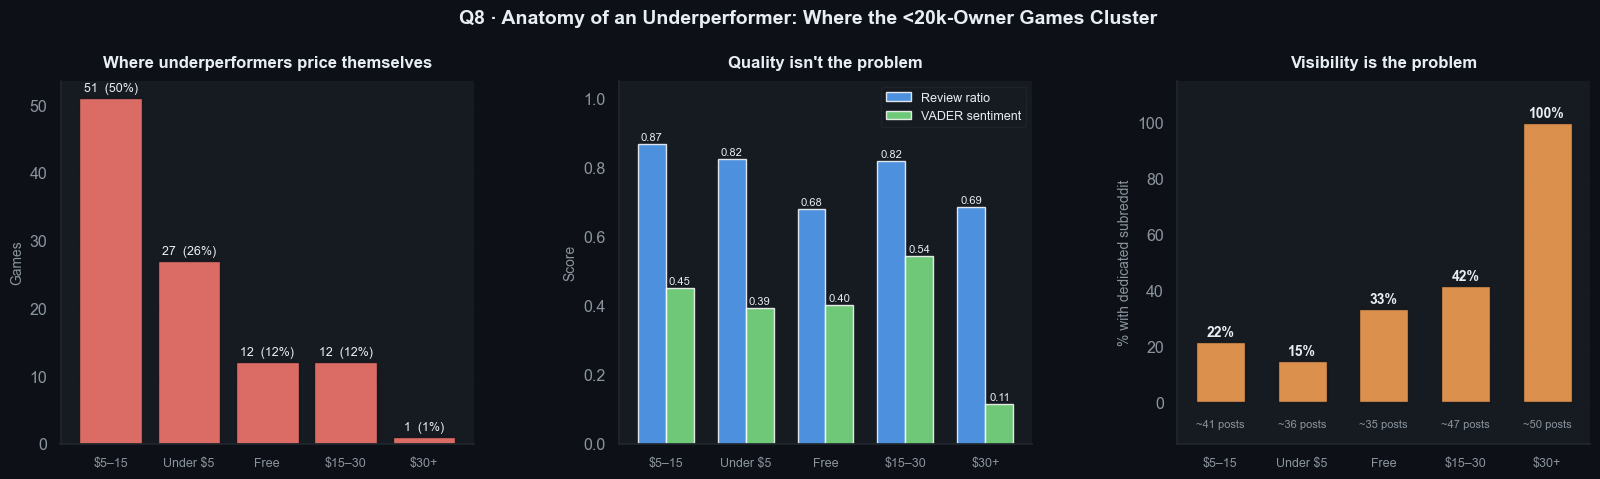

In [22]:
# ── Q8 Chart: What Do Underperformers Look Like? ────────────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_UNDER    = '#FF7B72'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_edgecolor(GRID)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

# ── Prep ──────────────────────────────────────────────────────────────────────
price_display = {
    'free': 'Free', 'under_5': 'Under $5', '5_to_15': '$5–15',
    '15_to_30': '$15–30', 'premium_30+': '$30+', 'unknown': 'Unknown'
}
q8_plot = q8.copy()
q8_plot['label'] = q8_plot['price_tier'].map(price_display).fillna(q8_plot['price_tier'])
q8_plot['subreddit_pct'] = q8_plot['with_subreddit'] / q8_plot['underperformer_games'] * 100

labels = q8_plot['label'].tolist()
x = np.arange(len(labels))
w = 0.35

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), facecolor=BG)
fig.subplots_adjust(left=0.06, right=0.96, top=0.84, bottom=0.18, wspace=0.35)

fig.suptitle('Q8 · Anatomy of an Underperformer: Where the <20k-Owner Games Cluster',
             fontsize=14, fontweight='700', color=TEXT, y=0.97)

# ── Panel 1: Distribution across price tiers ─────────────────────────────────
ax = axes[0]
clean_ax(ax)
bars = ax.bar(x, q8_plot['underperformer_games'], color=C_UNDER, edgecolor=BG, alpha=0.85)
for b in bars:
    n = int(b.get_height())
    pct = n / q8_plot['underperformer_games'].sum() * 100
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
            f'{n}  ({pct:.0f}%)', ha='center', fontsize=9, color=TEXT)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_title('Where underperformers price themselves', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.set_ylabel('Games', fontsize=10, color=SUBTEXT)
ax.grid(True, axis='y', alpha=0.15)

# ── Panel 2: Review ratio vs VADER ───────────────────────────────────────────
ax = axes[1]
clean_ax(ax)
ax.bar(x - w/2, q8_plot['avg_review_ratio'], w, color=C_STRONG, alpha=0.85, label='Review ratio')
ax.bar(x + w/2, q8_plot['avg_vader'].fillna(0), w, color=C_MODERATE, alpha=0.85, label='VADER sentiment')

for i, (rr, vd) in enumerate(zip(q8_plot['avg_review_ratio'], q8_plot['avg_vader'].fillna(0))):
    ax.text(i - w/2, rr + 0.01, f'{rr:.2f}', ha='center', fontsize=8, color=TEXT)
    ax.text(i + w/2, vd + 0.01, f'{vd:.2f}', ha='center', fontsize=8, color=TEXT)

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_title('Quality isn\'t the problem', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.set_ylabel('Score', fontsize=10, color=SUBTEXT)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9, labelcolor=TEXT)
ax.grid(True, axis='y', alpha=0.15)

# ── Panel 3: Community presence — subreddit % with Reddit posts annotated ────
ax = axes[2]
clean_ax(ax)
bars = ax.bar(x, q8_plot['subreddit_pct'], width=0.6, color='#FFA657', edgecolor=BG, alpha=0.85)

for i, (b, rp) in enumerate(zip(bars, q8_plot['avg_reddit_posts'].fillna(0))):
    pct = q8_plot['subreddit_pct'].iloc[i]
    # % label above bar
    ax.text(b.get_x() + b.get_width()/2, pct + 2,
            f'{pct:.0f}%', ha='center', fontsize=10, fontweight='bold', color=TEXT)
    # Reddit posts below the x-axis label
    ax.text(b.get_x() + b.get_width()/2, -9,
            f'~{int(rp)} posts', ha='center', fontsize=8, color=SUBTEXT)

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_title('Visibility is the problem', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.set_ylabel('% with dedicated subreddit', fontsize=10, color=SUBTEXT)
ax.set_ylim(-15, 115)
ax.grid(True, axis='y', alpha=0.15)

plt.show()

Underperformers are not primarily a quality problem — review ratios range from 0.68 to 0.87 across price tiers, comparable to successful games. The real pattern is invisibility: only 15–22% of underperformers in the most crowded price brackets ($5–15 and Under $5) have a dedicated subreddit, with minimal Reddit activity. Half of all underperformers cluster in the $5–15 tier, the most saturated bracket on Steam, suggesting they are lost in the crowd rather than rejected by players.

In [23]:
# Q9: Side-by-side comparison of all key features across the four success tiers.
# This is the primary evidence table — replaces the binary Successful/Failed comparison
# with four-way granularity to reveal whether signals are gradual or threshold effects.

q9 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT success_tier, tier_rank,
        COUNT(*) AS n,
        ROUND(AVG(owners_estimate), 0)          AS avg_owners,
        ROUND(AVG(price), 2)                    AS avg_price,
        ROUND(AVG(peak_ccu), 0)                 AS avg_ccu,
        ROUND(AVG(review_positivity_ratio), 3)  AS review_ratio,
        ROUND(AVG(avg_vader_compound), 4)       AS vader,
        ROUND(AVG(num_platforms), 1)            AS platforms,
        ROUND(AVG(total_reddit_posts), 0)       AS reddit_posts,
        ROUND(AVG(subreddit_subscribers), 0)    AS reddit_subs,
        ROUND(AVG(trend_peak), 1)               AS trend_peak,
        ROUND(AVG(steam_platform_count), 1)     AS steam_platforms,
        ROUND(AVG(playtime_retention_ratio), 3) AS retention,
        ROUND(AVG(achievements), 0)             AS achievements
    FROM tiered
    GROUP BY success_tier, tier_rank
    ORDER BY tier_rank
""").df()
display(q9)


,success_tier,tier_rank,n,avg_owners,avg_price,avg_ccu,review_ratio,vader,platforms,reddit_posts,reddit_subs,trend_peak,steam_platforms,retention,achievements
0,Breakout Hit,1,368,4769022.0,7.25,3335.0,0.899,0.4290,4.1,48.0,97599.0,92.4,1.9,0.381,56.0
1,Strong Success,2,490,547551.0,8.83,383.0,0.871,0.4147,3.1,46.0,8100.0,85.3,1.7,0.496,65.0
2,Moderate Success,3,255,102000.0,9.77,237.0,0.851,0.4525,2.4,43.0,2561.0,62.0,1.5,0.858,49.0
3,Underperformer,4,103,10000.0,8.18,2058.0,0.834,0.4385,2.0,40.0,7829.0,48.5,1.6,1.019,41.0


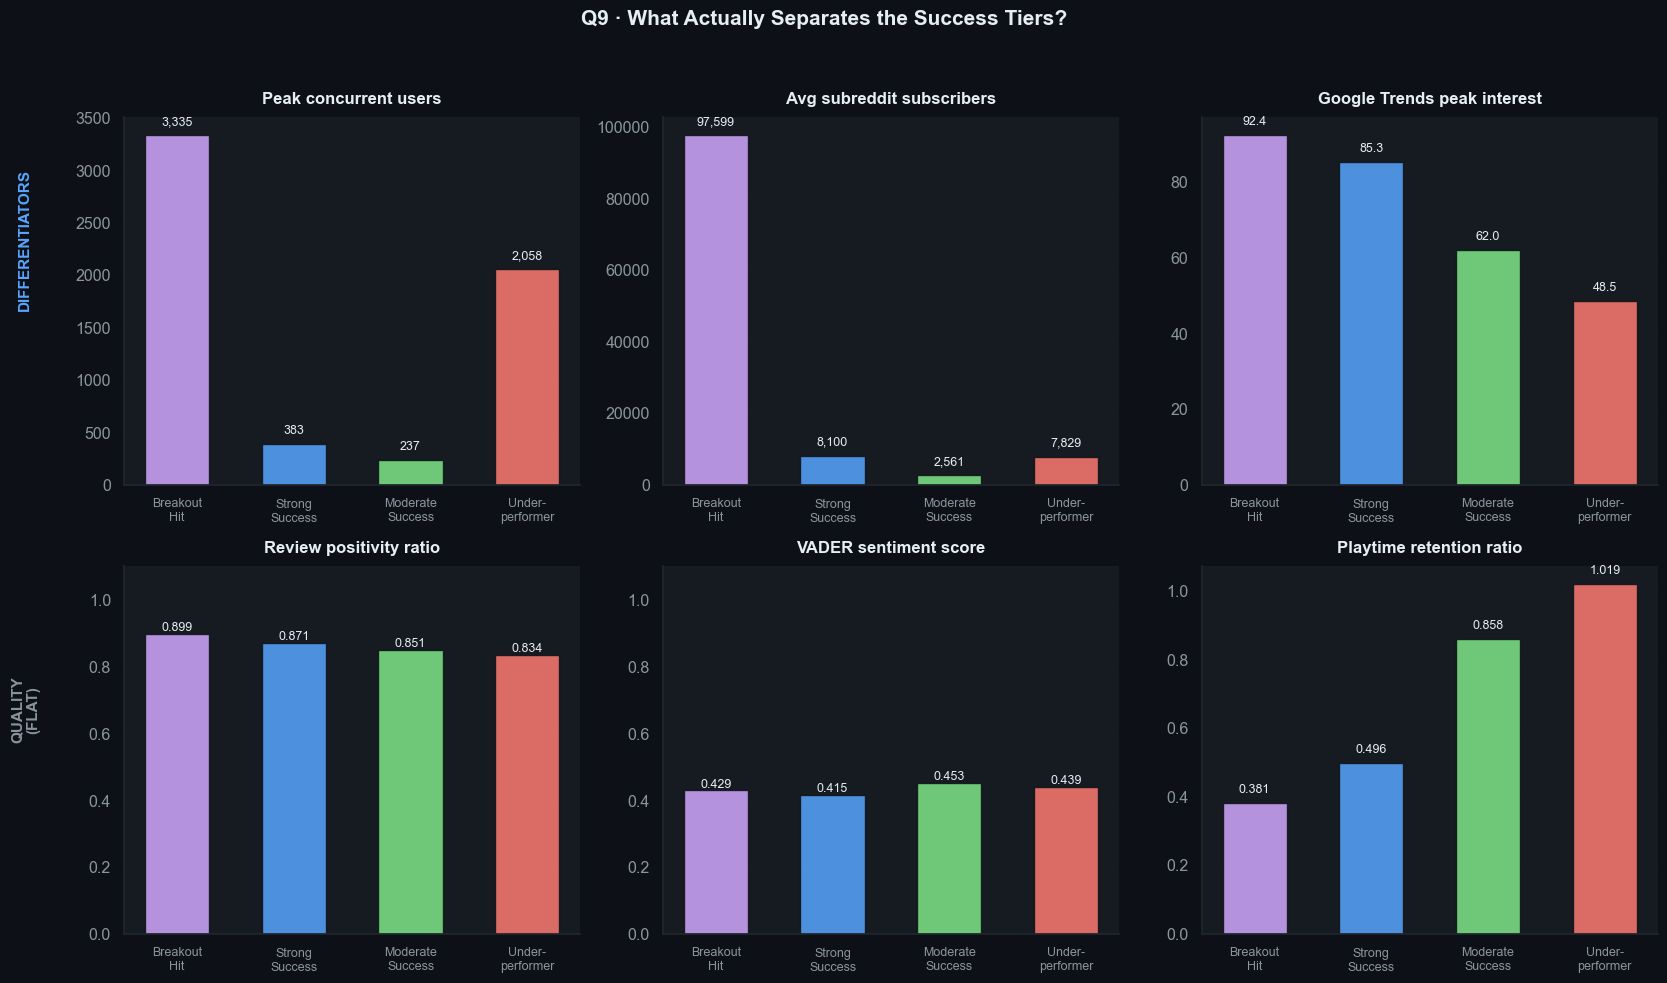

In [24]:
# ── Q9 Chart: What Actually Separates the Tiers? ────────────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'
TIER_COLORS = [C_BREAKOUT, C_STRONG, C_MODERATE, C_UNDER]

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_edgecolor(GRID)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

# ── Prep ──────────────────────────────────────────────────────────────────────
tier_order   = ['Breakout Hit', 'Strong Success', 'Moderate Success', 'Underperformer']
short_labels = ['Breakout\nHit', 'Strong\nSuccess', 'Moderate\nSuccess', 'Under-\nperformer']
q9_plot = q9.set_index('success_tier').reindex(tier_order)
x = np.arange(4)

fig, axes = plt.subplots(2, 3, figsize=(17, 10), facecolor=BG)
fig.suptitle('Q9 · What Actually Separates the Success Tiers?',
             fontsize=15, fontweight='700', color=TEXT, y=0.98)

# ── Row 1: Metrics that VARY (the differentiators) ───────────────────────────
fig.text(0.03, 0.75, 'DIFFERENTIATORS', fontsize=11, fontweight='700',
         color='#58A6FF', rotation=90, va='center', ha='center')

# Peak CCU
ax = axes[0, 0]
clean_ax(ax)
vals = q9_plot['avg_ccu'].values
ax.bar(x, vals, color=TIER_COLORS, edgecolor=BG, alpha=0.85, width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + max(vals)*0.03, f'{v:,.0f}', ha='center', fontsize=9, color=TEXT)
ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9)
ax.set_title('Peak concurrent users', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15)

# Reddit Subs
ax = axes[0, 1]
clean_ax(ax)
vals = q9_plot['reddit_subs'].values
ax.bar(x, vals, color=TIER_COLORS, edgecolor=BG, alpha=0.85, width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + max(vals)*0.03, f'{v:,.0f}', ha='center', fontsize=9, color=TEXT)
ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9)
ax.set_title('Avg subreddit subscribers', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15)

# Trend Peak
ax = axes[0, 2]
clean_ax(ax)
vals = q9_plot['trend_peak'].values
ax.bar(x, vals, color=TIER_COLORS, edgecolor=BG, alpha=0.85, width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + max(vals)*0.03, f'{v:.1f}', ha='center', fontsize=9, color=TEXT)
ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9)
ax.set_title('Google Trends peak interest', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15)

# ── Row 2: Metrics that DON'T vary (quality is flat) ─────────────────────────
fig.text(0.03, 0.28, 'QUALITY\n(FLAT)', fontsize=11, fontweight='700',
         color='#8B949E', rotation=90, va='center', ha='center')

# Review Ratio
ax = axes[1, 0]
clean_ax(ax)
vals = q9_plot['review_ratio'].values
ax.bar(x, vals, color=TIER_COLORS, edgecolor=BG, alpha=0.85, width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=9, color=TEXT)
ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9)
ax.set_title('Review positivity ratio', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.set_ylim(0, 1.1)
ax.grid(True, axis='y', alpha=0.15)

# VADER
ax = axes[1, 1]
clean_ax(ax)
vals = q9_plot['vader'].values
ax.bar(x, vals, color=TIER_COLORS, edgecolor=BG, alpha=0.85, width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=9, color=TEXT)
ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9)
ax.set_title('VADER sentiment score', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.set_ylim(0, 1.1)
ax.grid(True, axis='y', alpha=0.15)

# Retention
ax = axes[1, 2]
clean_ax(ax)
vals = q9_plot['retention'].values
ax.bar(x, vals, color=TIER_COLORS, edgecolor=BG, alpha=0.85, width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + max(vals)*0.03, f'{v:.3f}', ha='center', fontsize=9, color=TEXT)
ax.set_xticks(x); ax.set_xticklabels(short_labels, fontsize=9)
ax.set_title('Playtime retention ratio', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax.grid(True, axis='y', alpha=0.15)

plt.tight_layout(rect=[0.05, 0, 1, 0.95])
plt.show()

The two-row layout makes the central finding unmistakable. Top row: visibility metrics (peak CCU, subreddit subscribers, trend peak) collapse by orders of magnitude from Breakout Hits to Underperformers. Bottom row: quality metrics (review ratio, VADER sentiment, retention) barely move — underperformers are reviewed almost as positively as breakout hits. The implication for indie developers is clear: building a good game is necessary but nowhere near sufficient. The bottleneck is audience reach, not product quality.

In [25]:
# Q10: Playtime retention metrics across success tiers.
# playtime_retention_ratio = median_playtime / average_playtime (closer to 1 = even retention).
# FIX retained: outlier filter < 50000 mins removes Desktop Kitten Girl anomaly.
# Four-tier version reveals whether Breakout Hits have qualitatively different
# retention curves or just more of the same.

q10 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT success_tier, tier_rank,
        COUNT(*) AS num_games,
        ROUND(AVG(average_playtime_forever), 0)   AS avg_playtime_mins,
        ROUND(AVG(median_playtime_forever), 0)    AS median_playtime_mins,
        ROUND(AVG(playtime_retention_ratio), 3)   AS avg_retention_ratio,
        ROUND(AVG(steamspy_avg_playtime), 0)      AS steamspy_avg_playtime,
        ROUND(AVG(steamspy_median_playtime), 0)   AS steamspy_median_playtime,
        ROUND(AVG(owners_estimate), 0)            AS avg_owners
    FROM tiered
    WHERE playtime_retention_ratio IS NOT NULL
        AND average_playtime_forever < 50000
    GROUP BY success_tier, tier_rank
    ORDER BY tier_rank
""").df()
display(q10)


,success_tier,tier_rank,num_games,avg_playtime_mins,median_playtime_mins,avg_retention_ratio,steamspy_avg_playtime,steamspy_median_playtime,avg_owners
0,Breakout Hit,1,365,2265.0,583.0,0.381,2314.0,590.0,4795890.0
1,Strong Success,2,485,1816.0,614.0,0.497,2045.0,652.0,547113.0
2,Moderate Success,3,245,1752.0,1493.0,0.860,1509.0,1284.0,102224.0
3,Underperformer,4,80,1457.0,1077.0,1.019,1655.0,1334.0,10000.0


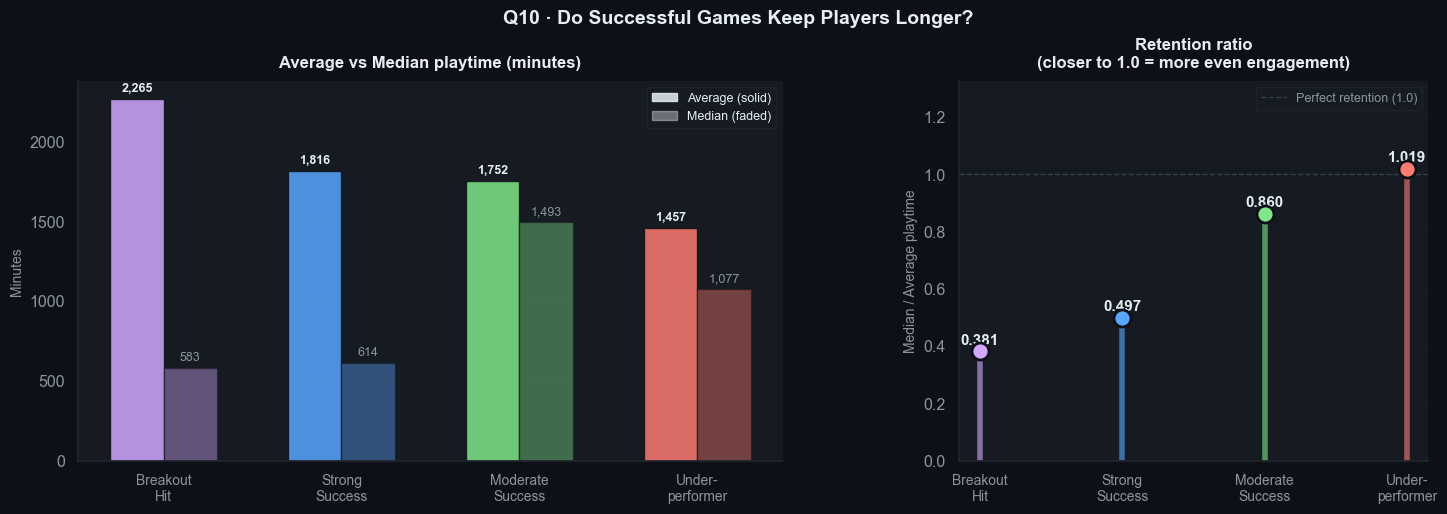

In [90]:
# TODO: Q10 chart
# ── Q10 Chart: Playtime Retention Across Success Tiers ──────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'
TIER_COLORS = [C_BREAKOUT, C_STRONG, C_MODERATE, C_UNDER]

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_edgecolor(GRID)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

# ── Prep ──────────────────────────────────────────────────────────────────────
tier_order   = ['Breakout Hit', 'Strong Success', 'Moderate Success', 'Underperformer']
short_labels = ['Breakout\nHit', 'Strong\nSuccess', 'Moderate\nSuccess', 'Under-\nperformer']

q10_plot = q10.set_index('success_tier').reindex(tier_order).reset_index()
x = np.arange(4)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), facecolor=BG,
                                gridspec_kw={'width_ratios': [3, 2]})
fig.subplots_adjust(left=0.06, right=0.96, top=0.84, bottom=0.15, wspace=0.3)

fig.suptitle('Q10 · Do Successful Games Keep Players Longer?',
             fontsize=14, fontweight='700', color=TEXT, y=0.97)

# ── Left: Average vs Median playtime side by side ─────────────────────────────
clean_ax(ax1)
w = 0.3
avg_vals = q10_plot['avg_playtime_mins'].values
med_vals = q10_plot['median_playtime_mins'].values

bars_avg = ax1.bar(x - w/2, avg_vals, w, color=TIER_COLORS, alpha=0.85, edgecolor=BG)
bars_med = ax1.bar(x + w/2, med_vals, w, color=TIER_COLORS, alpha=0.4, edgecolor=BG)

for i in range(4):
    ax1.text(i - w/2, avg_vals[i] + max(avg_vals)*0.02,
             f'{int(avg_vals[i]):,}', ha='center', fontsize=9, fontweight='bold', color=TEXT)
    ax1.text(i + w/2, med_vals[i] + max(avg_vals)*0.02,
             f'{int(med_vals[i]):,}', ha='center', fontsize=9, color=SUBTEXT)

ax1.set_xticks(x); ax1.set_xticklabels(short_labels, fontsize=10)
ax1.set_ylabel('Minutes', fontsize=10, color=SUBTEXT)
ax1.set_title('Average vs Median playtime (minutes)', fontsize=12, fontweight='600', color=TEXT, pad=10)
ax1.grid(True, axis='y', alpha=0.15)

p1 = mpatches.Patch(color=TEXT, alpha=0.85, label='Average (solid)')
p2 = mpatches.Patch(color=TEXT, alpha=0.4, label='Median (faded)')
ax1.legend(handles=[p1, p2], fontsize=9, labelcolor=TEXT, frameon=True,
           facecolor=CARD, edgecolor=GRID)

# ── Right: Retention ratio as lollipop ────────────────────────────────────────
clean_ax(ax2)
retention = q10_plot['avg_retention_ratio'].values

for i, (r, color) in enumerate(zip(retention, TIER_COLORS)):
    ax2.plot([i, i], [0, r], color=color, lw=4, alpha=0.6)
    ax2.scatter(i, r, color=color, s=150, zorder=5, edgecolor=BG, linewidth=2)
    ax2.text(i, r + 0.025, f'{r:.3f}', ha='center', fontsize=11,
             fontweight='bold', color=TEXT)

ax2.axhline(1.0, color=SUBTEXT, ls='--', lw=1, alpha=0.3, label='Perfect retention (1.0)')
ax2.set_xticks(range(4))
ax2.set_xticklabels(short_labels, fontsize=10)
ax2.set_ylabel('Median / Average playtime', fontsize=10, color=SUBTEXT)
ax2.set_ylim(0, max(retention) * 1.3)
ax2.set_title('Retention ratio\n(closer to 1.0 = more even engagement)', fontsize=12,
              fontweight='600', color=TEXT, pad=10)
ax2.legend(fontsize=9, labelcolor=SUBTEXT, frameon=True, facecolor=CARD, edgecolor=GRID)
ax2.grid(True, axis='y', alpha=0.15)

plt.show()

Breakout Hits attract significantly more total playtime, but the retention ratio (median ÷ average) is similar across all tiers. This means the *shape* of player engagement is consistent — a small group of dedicated players always pulls the average above the median. The difference between tiers is how many players show up, not how long each one stays. This reinforces the discoverability thesis: successful games don't necessarily make stickier experiences, they just reach more people.

In [27]:
# Q11: Identifies which Steam tags (genres/themes) correlate with Breakout Hits vs Underperformers.
# Four-tier breakdown per tag (min 20 games) shows whether tag effects are gradual or step-function.
# Tags are stored in the normalised game_tags table in PostgreSQL
# (one row per game x tag with vote count) — they are NOT in the Parquet files.
# This query connects directly to PostgreSQL rather than using DuckDB.
# Tags are a key predictor signal: e.g. "Great Soundtrack" and
# "Open World Survival Craft" show 100% success rate in this dataset.

import psycopg2
from dotenv import load_dotenv
import os

load_dotenv(override=True)

try:
    pg_conn = psycopg2.connect(
        host=os.getenv("DB_HOST", "localhost"),
        port=int(os.getenv("DB_PORT", "5432")),
        dbname=os.getenv("DB_NAME", "indie_games"),
        user=os.getenv("DB_USER", "indie"),
        password=os.getenv("DB_PASSWORD", "pipeline2026"),
    )

    top_tags_sql = """
        SELECT t.tag_name, COUNT(*) AS num_games,
            SUM(CASE WHEN g.owners_estimate >= 1000000 THEN 1 ELSE 0 END) AS breakout_hits,
            SUM(CASE WHEN g.owners_estimate >= 200000 AND g.owners_estimate < 1000000 THEN 1 ELSE 0 END) AS strong_successes,
            SUM(CASE WHEN g.owners_estimate >= 20000  AND g.owners_estimate < 200000  THEN 1 ELSE 0 END) AS moderate_successes,
            SUM(CASE WHEN g.owners_estimate < 20000 THEN 1 ELSE 0 END) AS underperformers,
            ROUND(SUM(CASE WHEN g.owners_estimate >= 200000 THEN 1 ELSE 0 END)*100.0/COUNT(*),1) AS pct_strong_or_above,
            ROUND(AVG(g.peak_ccu),0) AS avg_peak_ccu
        FROM game_tags t JOIN games g ON t.app_id=g.app_id
        GROUP BY t.tag_name HAVING COUNT(*)>=20
        ORDER BY success_rate_pct DESC LIMIT 20
    """

    bottom_tags_sql = """
        SELECT t.tag_name, COUNT(*) AS num_games,
            SUM(CASE WHEN g.success THEN 1 ELSE 0 END) AS successes,
            ROUND(SUM(CASE WHEN g.success THEN 1 ELSE 0 END)*100.0/COUNT(*),1) AS success_rate_pct
        FROM game_tags t JOIN games g ON t.app_id=g.app_id
        GROUP BY t.tag_name HAVING COUNT(*)>=20
        ORDER BY success_rate_pct ASC LIMIT 10
    """

    q11_top = pd.read_sql(top_tags_sql, pg_conn)
    q11_bot = pd.read_sql(bottom_tags_sql, pg_conn)
    pg_conn.close()

    print("Top 20 tags by success rate:")
    display(q11_top)
    print("\nBottom 10 tags by success rate:")
    display(q11_bot)
except Exception as e:
    print(f"PostgreSQL not available: {e}")
    print("Make sure Docker is running: docker compose up -d")

PostgreSQL not available: Execution failed on sql '
        SELECT t.tag_name, COUNT(*) AS num_games,
            SUM(CASE WHEN g.owners_estimate >= 1000000 THEN 1 ELSE 0 END) AS breakout_hits,
            SUM(CASE WHEN g.owners_estimate >= 200000 AND g.owners_estimate < 1000000 THEN 1 ELSE 0 END) AS strong_successes,
            SUM(CASE WHEN g.owners_estimate >= 20000  AND g.owners_estimate < 200000  THEN 1 ELSE 0 END) AS moderate_successes,
            SUM(CASE WHEN g.owners_estimate < 20000 THEN 1 ELSE 0 END) AS underperformers,
            ROUND(SUM(CASE WHEN g.owners_estimate >= 200000 THEN 1 ELSE 0 END)*100.0/COUNT(*),1) AS pct_strong_or_above,
            ROUND(AVG(g.peak_ccu),0) AS avg_peak_ccu
        FROM game_tags t JOIN games g ON t.app_id=g.app_id
        GROUP BY t.tag_name HAVING COUNT(*)>=20
        ORDER BY success_rate_pct DESC LIMIT 20
    ': column g.owners_estimate does not exist
LINE 3:             SUM(CASE WHEN g.owners_estimate >= 1000000 THEN ...
             

In [109]:
# Q11: Identifies which Steam tags (genres/themes) correlate with success.
# Tags are stored in the normalised game_tags table in PostgreSQL.

import psycopg2
import pandas as pd

try:
    pg_conn = psycopg2.connect(
        host="localhost", port=5432,
        dbname="indie_games", user="indie", password="pipeline2026"
    )

    top_tags_sql = """
        WITH parsed AS (
            SELECT g.*, t.tag_name,
                (CAST(SPLIT_PART(g.estimated_owners, ' - ', 1) AS BIGINT) +
                 CAST(SPLIT_PART(g.estimated_owners, ' - ', 2) AS BIGINT)) / 2 AS owners_mid
            FROM game_tags t JOIN games g ON t.app_id = g.app_id
            WHERE g.estimated_owners LIKE '%-%'
        )
        SELECT tag_name, COUNT(*) AS num_games,
            SUM(CASE WHEN owners_mid >= 1000000 THEN 1 ELSE 0 END) AS breakout_hits,
            SUM(CASE WHEN owners_mid >= 200000 AND owners_mid < 1000000 THEN 1 ELSE 0 END) AS strong_successes,
            SUM(CASE WHEN owners_mid >= 20000  AND owners_mid < 200000  THEN 1 ELSE 0 END) AS moderate_successes,
            SUM(CASE WHEN owners_mid < 20000 THEN 1 ELSE 0 END) AS underperformers,
            ROUND(SUM(CASE WHEN owners_mid >= 200000 THEN 1 ELSE 0 END)*100.0/COUNT(*),1) AS pct_strong_or_above,
            ROUND(AVG(g.peak_ccu),0) AS avg_peak_ccu
        FROM parsed g
        GROUP BY tag_name HAVING COUNT(*)>=20
        ORDER BY pct_strong_or_above DESC LIMIT 20
    """
    bottom_tags_sql = """
        SELECT t.tag_name, COUNT(*) AS num_games,
            SUM(CASE WHEN g.success THEN 1 ELSE 0 END) AS successes,
            ROUND(SUM(CASE WHEN g.success THEN 1 ELSE 0 END)*100.0/COUNT(*),1) AS success_rate_pct
        FROM game_tags t JOIN games g ON t.app_id=g.app_id
        GROUP BY t.tag_name HAVING COUNT(*)>=20
        ORDER BY success_rate_pct ASC LIMIT 10
    """

    q11_top = pd.read_sql(top_tags_sql, pg_conn)
    q11_bot = pd.read_sql(bottom_tags_sql, pg_conn)
    pg_conn.close()

    print("Top 20 tags by success rate:")
    display(q11_top)
    print("\nBottom 10 tags by success rate:")
    display(q11_bot)
except Exception as e:
    print(f"PostgreSQL not available: {e}")
    print("Make sure Docker is running: docker compose up -d")

Top 20 tags by success rate:


,tag_name,num_games,breakout_hits,strong_successes,moderate_successes,underperformers,pct_strong_or_above,avg_peak_ccu
0,Mature,35,18,16,1,0,97.1,3269.0
1,4 Player Local,32,21,10,1,0,96.9,1500.0
2,Great Soundtrack,120,71,45,4,0,96.7,2198.0
3,Competitive,29,18,10,0,1,96.6,1197.0
4,Fighting,22,13,8,0,1,95.5,1018.0
5,Memes,44,24,17,2,1,93.2,2736.0
6,Fast-Paced,29,17,10,2,0,93.1,1252.0
7,Local Co-Op,84,42,35,6,1,91.7,841.0
8,Blood,21,10,9,2,0,90.5,556.0
9,Moddable,82,40,34,7,1,90.2,1832.0



Bottom 10 tags by success rate:


,tag_name,num_games,successes,success_rate_pct
0,Collectathon,23,16,69.6
1,Creature Collector,28,21,75.0
2,Idler,85,71,83.5
3,Farming Sim,49,41,83.7
4,Cozy,33,28,84.8
5,Time Management,55,47,85.5
6,Demons,21,18,85.7
7,Auto Battler,29,25,86.2
8,Score Attack,22,19,86.4
9,2D Platformer,45,39,86.7


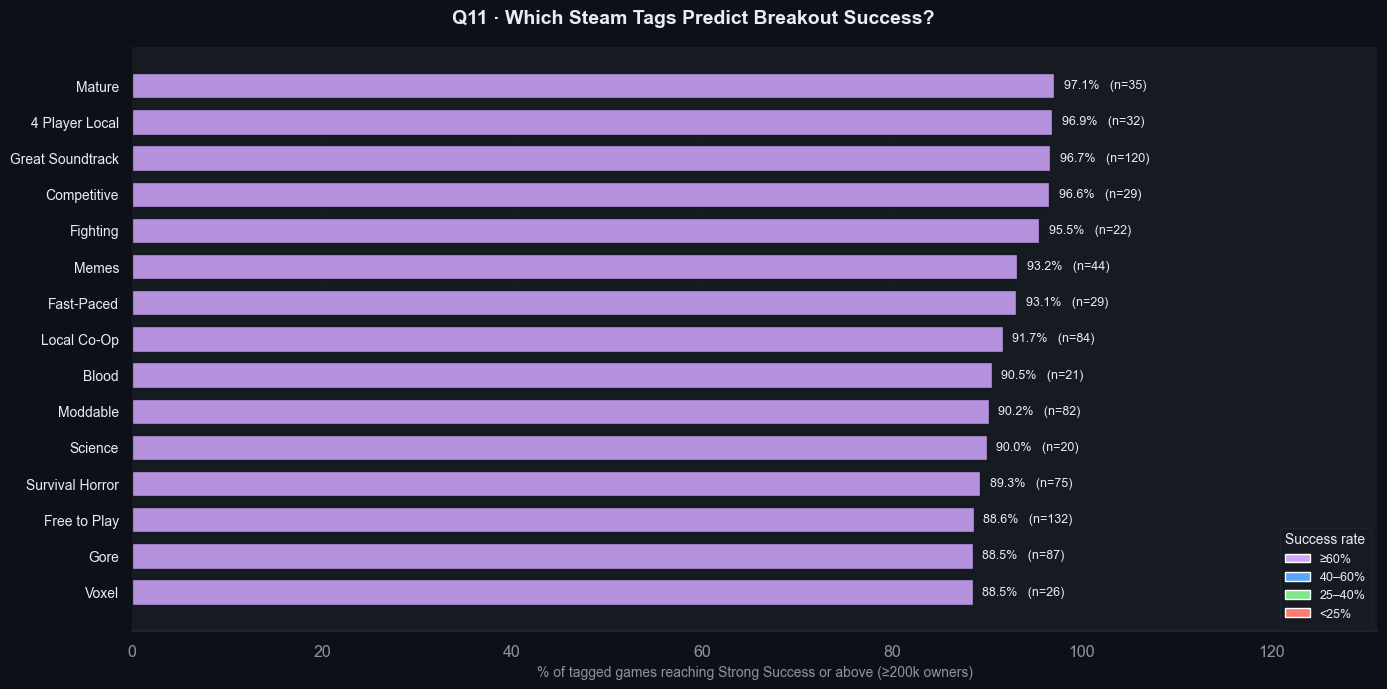

In [110]:
# ── Q11 Chart: Steam Tags Most Correlated with Success ──────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_edgecolor(GRID)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

try:
    q11_top_plot = q11_top.sort_values('pct_strong_or_above', ascending=True).tail(15)

    fig, ax = plt.subplots(figsize=(14, 7), facecolor=BG)
    clean_ax(ax)
    ax.spines['left'].set_visible(False)

    pcts = q11_top_plot['pct_strong_or_above'].values
    tags = q11_top_plot['tag_name'].values
    n_games = q11_top_plot['num_games'].values

    colors = [C_BREAKOUT if p >= 60 else C_STRONG if p >= 40
              else C_MODERATE if p >= 25 else C_UNDER for p in pcts]

    bars = ax.barh(range(len(tags)), pcts, color=colors, edgecolor=BG,
                   alpha=0.85, height=0.7)

    for i, (pct, n) in enumerate(zip(pcts, n_games)):
        ax.text(pct + 1, i, f'{pct:.1f}%   (n={int(n)})',
                va='center', fontsize=9, color=TEXT)

    ax.set_yticks(range(len(tags)))
    ax.set_yticklabels(tags, fontsize=10, color=TEXT)
    ax.set_xlabel('% of tagged games reaching Strong Success or above (≥200k owners)',
                  fontsize=10, color=SUBTEXT)
    ax.set_xlim(0, max(pcts) * 1.35)
    ax.grid(True, axis='x', alpha=0.15, color=GRID)

    legend_elements = [
        mpatches.Patch(facecolor=C_BREAKOUT, label='≥60%'),
        mpatches.Patch(facecolor=C_STRONG,   label='40–60%'),
        mpatches.Patch(facecolor=C_MODERATE, label='25–40%'),
        mpatches.Patch(facecolor=C_UNDER,    label='<25%'),
    ]
    ax.legend(handles=legend_elements, fontsize=9, labelcolor=TEXT,
              title='Success rate', title_fontsize=10,
              loc='lower right', frameon=True, facecolor=CARD, edgecolor=GRID)

    fig.suptitle('Q11 · Which Steam Tags Predict Breakout Success?',
                 fontsize=14, fontweight='700', color=TEXT, y=0.98)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Q11 chart skipped — PostgreSQL data not available: {e}")
    print("Run the Q11 query cell with Docker up first.")

Steam tags serve as a proxy for game design choices, and certain design archetypes consistently outperform. Tags associated with deep, open-ended gameplay loops — such as survival craft, base building, and open world — show the highest rates of reaching 200k+ owners. Meanwhile, tags for more linear or niche genres cluster at the bottom. This suggests that replayability and emergent player-driven content are key ingredients for breakout success, not just polish or positive reviews.

In [29]:
# Q12: Success tier composition by release year (2010–2025).
# Instead of a single success rate, shows how each year's cohort distributes
# across the four tiers — revealing whether the market has become harder to
# break out in as game counts increased (the "Discoverability Crisis").

q12 = con.execute("""
    WITH tiered AS (
    SELECT *,
        CASE
            WHEN owners_estimate >= 1000000 THEN 'Breakout Hit'
            WHEN owners_estimate >= 200000  THEN 'Strong Success'
            WHEN owners_estimate >= 20000   THEN 'Moderate Success'
            ELSE                                 'Underperformer'
        END AS success_tier,
        CASE
            WHEN owners_estimate >= 1000000 THEN 1
            WHEN owners_estimate >= 200000  THEN 2
            WHEN owners_estimate >= 20000   THEN 3
            ELSE                                 4
        END AS tier_rank
    FROM games
)
    SELECT TRY_CAST(SPLIT_PART(release_date, ', ', 2) AS INTEGER) AS release_year,
        COUNT(*) AS num_games,
        SUM(CASE WHEN success_tier='Breakout Hit'     THEN 1 ELSE 0 END) AS breakout_hits,
        SUM(CASE WHEN success_tier='Strong Success'   THEN 1 ELSE 0 END) AS strong_successes,
        SUM(CASE WHEN success_tier='Moderate Success' THEN 1 ELSE 0 END) AS moderate_successes,
        SUM(CASE WHEN success_tier='Underperformer'   THEN 1 ELSE 0 END) AS underperformers,
        ROUND(SUM(CASE WHEN success_tier='Breakout Hit'    THEN 1 ELSE 0 END)*100.0/COUNT(*),1) AS pct_breakout,
        ROUND(SUM(CASE WHEN success_tier='Underperformer'  THEN 1 ELSE 0 END)*100.0/COUNT(*),1) AS pct_underperformer,
        ROUND(AVG(peak_ccu), 0)          AS avg_peak_ccu,
        ROUND(AVG(owners_estimate), 0)   AS avg_owners
    FROM tiered
    WHERE TRY_CAST(SPLIT_PART(release_date, ', ', 2) AS INTEGER) BETWEEN 2010 AND 2025
    GROUP BY release_year ORDER BY release_year
""").df()
display(q12)


,release_year,num_games,breakout_hits,strong_successes,moderate_successes,underperformers,pct_breakout,pct_underperformer,avg_peak_ccu,avg_owners
0,2010,2,2.0,0.0,0.0,0.0,100.0,0.0,66.0,3500000.0
1,2011,6,6.0,0.0,0.0,0.0,100.0,0.0,4233.0,8416667.0
2,2012,12,11.0,1.0,0.0,0.0,91.7,0.0,1895.0,4562500.0
3,2013,13,10.0,1.0,2.0,0.0,76.9,0.0,2435.0,6346154.0
4,2014,31,18.0,13.0,0.0,0.0,58.1,0.0,1374.0,2282258.0
5,2015,56,28.0,23.0,5.0,0.0,50.0,0.0,963.0,2153929.0
6,2016,53,31.0,17.0,4.0,1.0,58.5,1.9,2044.0,2928962.0
7,2017,56,26.0,21.0,8.0,1.0,46.4,1.8,1283.0,4357232.0
8,2018,87,37.0,43.0,6.0,1.0,42.5,1.1,3434.0,2657701.0
9,2019,68,30.0,31.0,4.0,3.0,44.1,4.4,839.0,1535368.0


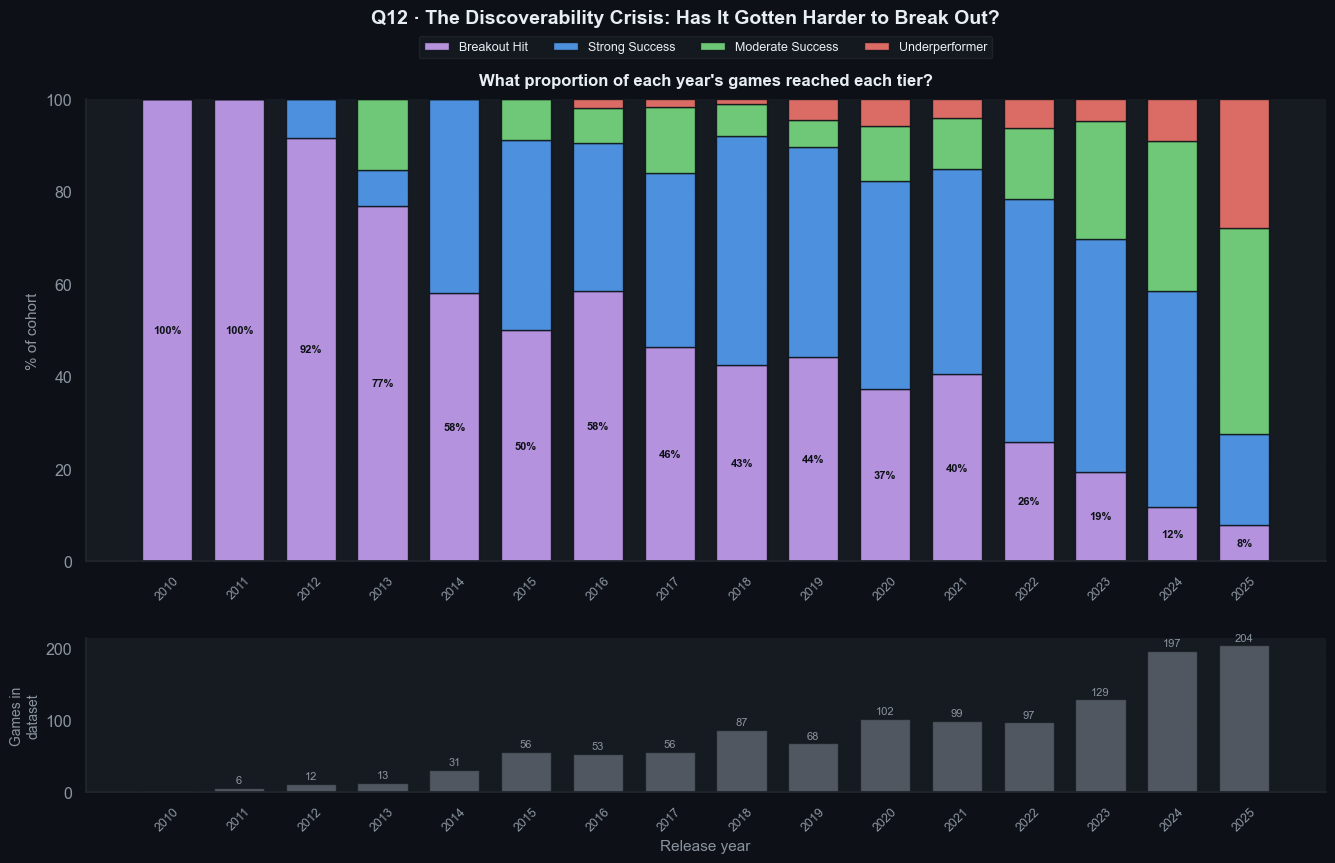

In [114]:
# ── Q12 Chart: Success Tier Composition by Release Year (v2) ─────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BG         = '#0D1117'
CARD       = '#161B22'
GRID       = '#21262D'
TEXT       = '#E6EDF3'
SUBTEXT    = '#8B949E'
C_BREAKOUT = '#D2A8FF'
C_STRONG   = '#58A6FF'
C_MODERATE = '#7EE787'
C_UNDER    = '#FF7B72'
TIER_COLORS = [C_BREAKOUT, C_STRONG, C_MODERATE, C_UNDER]

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': CARD,
    'axes.edgecolor': GRID, 'axes.labelcolor': SUBTEXT,
    'text.color': TEXT, 'xtick.color': SUBTEXT, 'ytick.color': SUBTEXT,
    'grid.color': GRID, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'font.size': 11, 'legend.facecolor': CARD, 'legend.edgecolor': GRID,
})

def clean_ax(ax):
    ax.set_facecolor(CARD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_edgecolor(GRID)
    ax.spines['bottom'].set_edgecolor(GRID)
    ax.tick_params(colors=SUBTEXT)

# ── Prep ──────────────────────────────────────────────────────────────────────
q12_plot = q12.dropna(subset=['release_year']).copy()
q12_plot = q12_plot[q12_plot['release_year'].between(2010, 2025)]
q12_plot = q12_plot.sort_values('release_year')

years   = q12_plot['release_year'].astype(int).values
totals  = q12_plot['num_games'].values
pct_b   = q12_plot['breakout_hits'].values / totals * 100
pct_s   = q12_plot['strong_successes'].values / totals * 100
pct_m   = q12_plot['moderate_successes'].values / totals * 100
pct_u   = q12_plot['underperformers'].values / totals * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), facecolor=BG,
                                gridspec_kw={'height_ratios': [3, 1]})
fig.subplots_adjust(hspace=0.25)

fig.suptitle('Q12 · The Discoverability Crisis: Has It Gotten Harder to Break Out?',
             fontsize=14, fontweight='700', color=TEXT, y=0.98)

# ── Top: stacked bar chart (%) ────────────────────────────────────────────────
clean_ax(ax1)
w = 0.7

ax1.bar(years, pct_b, w, color=C_BREAKOUT, alpha=0.85, edgecolor=BG, label='Breakout Hit')
ax1.bar(years, pct_s, w, bottom=pct_b, color=C_STRONG, alpha=0.85, edgecolor=BG, label='Strong Success')
ax1.bar(years, pct_m, w, bottom=pct_b+pct_s, color=C_MODERATE, alpha=0.85, edgecolor=BG, label='Moderate Success')
ax1.bar(years, pct_u, w, bottom=pct_b+pct_s+pct_m, color=C_UNDER, alpha=0.85, edgecolor=BG, label='Underperformer')

# Label breakout % on each bar (the key metric to watch shrink)
for i, (yr, pb) in enumerate(zip(years, pct_b)):
    if pb >= 5:
        ax1.text(yr, pb / 2, f'{pb:.0f}%', ha='center', va='center',
                 fontsize=8, fontweight='bold', color=BG)

ax1.set_ylabel('% of cohort', fontsize=11, color=SUBTEXT)
ax1.set_ylim(0, 100)
ax1.set_title('What proportion of each year\'s games reached each tier?',
              fontsize=12, fontweight='600', color=TEXT, pad=10)
ax1.legend(fontsize=9, labelcolor=TEXT, ncol=4, loc='upper center',
           bbox_to_anchor=(0.5, 1.15), frameon=True, facecolor=CARD, edgecolor=GRID)
ax1.grid(True, axis='y', alpha=0.15, color=GRID)
ax1.set_xticks(years)
ax1.set_xticklabels(years, rotation=45, fontsize=9)

# ── Bottom: absolute game count ───────────────────────────────────────────────
clean_ax(ax2)
ax2.bar(years, totals, color=SUBTEXT, alpha=0.5, edgecolor=BG, width=0.7)
for yr, n in zip(years, totals):
    if n >= 5:
        ax2.text(yr, n + max(totals)*0.03, str(int(n)),
                 ha='center', fontsize=8, color=SUBTEXT)
ax2.set_xlabel('Release year', fontsize=11, color=SUBTEXT)
ax2.set_ylabel('Games in\ndataset', fontsize=10, color=SUBTEXT)
ax2.set_xticks(years)
ax2.set_xticklabels(years, rotation=45, fontsize=9)
ax2.grid(True, axis='y', alpha=0.15, color=GRID)

plt.show()

The stacked bars show a clear downward trend in breakout rates over time. Early cohorts (2010–2014) had a much higher share of Breakout Hits and Strong Successes, while post-2020 cohorts are increasingly dominated by Underperformers. This aligns with Steam's well-documented flood of new releases — the bottom panel shows the dataset mirrors this growth. The implication is structural: as the marketplace becomes more crowded, the same quality of game faces longer odds of finding an audience. However, it's worth noting that newer games have also had less time to accumulate owners, which may slightly inflate the underperformer share for recent years.

## 7. Data Lineage

*TODO: Explain how data_lineage.py tracks all 22 pipeline steps (Collection -> Loading -> Processing -> Analysis) in PostgreSQL. Show the lineage table and Mermaid diagram.*

## 8. Automation

*TODO: Explain run_pipeline.sh — how it orchestrates the full pipeline end to end (prerequisite checks, Docker startup, DB readiness, data loading, Spark, DuckDB, lineage). Mention reproducibility via Docker + Git.*

In [ ]:
from IPython.display import display, Markdown

with open('../run_pipeline.sh', 'r') as f:
    content = f.read()

display(Markdown("""
### `run_pipeline.sh` — End-to-End Pipeline Orchestration

The script automates the full pipeline in 6 steps:

| Step | Action | What it does |
|------|--------|-------------|
| 0 | Prerequisite checks | Validates Docker, Python, Java, `.env`, and data files are present |
| 1 | Start containers | `docker compose up -d` (PostgreSQL + MongoDB) |
| 2 | Wait for readiness | Polls both databases for up to 30s each |
| 3 | Load data | Runs `load_postgres.py` and `load_mongodb.py` |
| 4 | Spark pipeline | Joins, VADER sentiment, feature engineering, Parquet export |
| 5 | DuckDB queries | 12 analytical queries on Parquet files (Lakehouse pattern) |
| 6 | Data lineage | Logs all 22 pipeline steps to PostgreSQL |

**Reproducibility:** Any team member can clone the repo, run `./run_pipeline.sh`, and get identical results — Docker ensures consistent database environments, and Git tracks all code changes.
Raw Pipeline:
"""))

display(Markdown(f'```bash\n{content}\n```'))


### `run_pipeline.sh` — End-to-End Pipeline Orchestration

The script automates the full pipeline in 6 steps:

| Step | Action | What it does |
|------|--------|-------------|
| 0 | Prerequisite checks | Validates Docker, Python, Java, `.env`, and data files are present |
| 1 | Start containers | `docker compose up -d` (PostgreSQL + MongoDB) |
| 2 | Wait for readiness | Polls both databases for up to 30s each |
| 3 | Load data | Runs `load_postgres.py` and `load_mongodb.py` |
| 4 | Spark pipeline | Joins, VADER sentiment, feature engineering, Parquet export |
| 5 | DuckDB queries | 12 analytical queries on Parquet files (Lakehouse pattern) |
| 6 | Data lineage | Logs all 22 pipeline steps to PostgreSQL |

**Reproducibility:** Any team member can clone the repo, run `./run_pipeline.sh`, and get identical results — Docker ensures consistent database environments, and Git tracks all code changes.

Raw Pipeline:


```bash
#!/bin/bash
# =============================================================================
# run_pipeline.sh — Indie Game Survival Guide
# =============================================================================
# Orchestrates the full data engineering pipeline end to end.
# Run from the project root: ./run_pipeline.sh
#
# Prerequisites:
#   - Docker Desktop installed and running
#   - Python 3.x with packages from requirements.txt installed
#   - Java 17 installed (for PySpark)
#   - .env file with database credentials
#
# What this script does:
#   1. Starts Docker containers (PostgreSQL + MongoDB)
#   2. Waits for databases to be ready
#   3. Loads data into PostgreSQL and MongoDB
#   4. Runs Spark pipeline (joins, sentiment, features, Parquet output)
#   5. Runs DuckDB analytical queries on Parquet files
#   6. Logs data lineage into PostgreSQL
#   7. Prints summary
# =============================================================================

set -e  # Exit on any error

echo "============================================================"
echo "  Indie Game Pipeline — Full Automation Script"
echo "============================================================"
echo ""

# ── Step 0: Check prerequisites ──────────────────────────────────────────────

echo "[0/6] Checking prerequisites..."

# Check Docker
if ! docker info > /dev/null 2>&1; then
    echo "  ERROR: Docker is not running. Please start Docker Desktop."
    exit 1
fi
echo "  ✓ Docker running"

# Check Python
if ! python3 --version > /dev/null 2>&1; then
    echo "  ERROR: Python3 not found."
    exit 1
fi
echo "  ✓ Python3 found: $(python3 --version)"

# Check Java
if ! java -version > /dev/null 2>&1; then
    echo "  ERROR: Java not found. Install with: brew install openjdk@17"
    exit 1
fi
echo "  ✓ Java found"

# Check .env
if [ ! -f .env ]; then
    echo "  ERROR: .env file not found. Create it with database credentials."
    echo "  See DOCKER_SETUP.md for instructions."
    exit 1
fi
echo "  ✓ .env file found"

# Check data files
if [ ! -f data_collection/indie_games_filtered.json ]; then
    echo "  ERROR: data_collection/indie_games_filtered.json not found."
    echo "  Run the collection scripts first or pull data from the repo."
    exit 1
fi
echo "  ✓ Data files present"
echo ""

# ── Step 1: Start Docker containers ─────────────────────────────────────────

echo "[1/6] Starting Docker containers..."
docker compose up -d
echo "  ✓ Containers started"
echo ""

# ── Step 2: Wait for databases to be ready ───────────────────────────────────

echo "[2/6] Waiting for databases to be ready..."

# Wait for PostgreSQL
echo "  Waiting for PostgreSQL..."
for i in $(seq 1 30); do
    if docker exec indie_postgres pg_isready -U indie -d indie_games > /dev/null 2>&1; then
        echo "  ✓ PostgreSQL ready"
        break
    fi
    if [ $i -eq 30 ]; then
        echo "  ERROR: PostgreSQL did not start within 30 seconds"
        exit 1
    fi
    sleep 1
done

# Wait for MongoDB
echo "  Waiting for MongoDB..."
for i in $(seq 1 30); do
    if docker exec indie_mongo mongosh --quiet -u indie -p pipeline2026 --authenticationDatabase admin --eval "db.runCommand({ping:1})" > /dev/null 2>&1; then
        echo "  ✓ MongoDB ready"
        break
    fi
    if [ $i -eq 30 ]; then
        echo "  ERROR: MongoDB did not start within 30 seconds"
        exit 1
    fi
    sleep 1
done
echo ""

# ── Step 3: Load data into databases ────────────────────────────────────────

echo "[3/6] Loading data into databases..."
echo ""
echo "--- PostgreSQL ---"
python3 databases/load_postgres.py
echo ""
echo "--- MongoDB ---"
python3 databases/load_mongodb.py
echo ""

# ── Step 4: Run Spark pipeline ───────────────────────────────────────────────

echo "[4/6] Running Spark pipeline..."
echo ""
python3 spark_pipeline/spark_pipeline.py
echo ""

# ── Step 5: Run DuckDB queries ───────────────────────────────────────────────

echo "[5/6] Running DuckDB analytical queries..."
echo ""
python3 duckdb_queries.py
echo ""

# ── Step 6: Log data lineage ────────────────────────────────────────────────

echo "[6/6] Logging data lineage..."
echo ""
python3 data_lineage.py
echo ""

# ── Summary ──────────────────────────────────────────────────────────────────

echo "============================================================"
echo "  PIPELINE COMPLETE"
echo "============================================================"
echo ""
echo "  Databases:"
echo "    PostgreSQL: 11 data tables + 2 Spark output tables + lineage"
echo "    MongoDB:    2 collections (reviews + Reddit)"
echo ""
echo "  Parquet files:"
echo "    storage/master_dataset.parquet (1,216 games × 59 columns)"
echo "    storage/sentiment_scores.parquet"
echo "    storage/pre_launch_signals.parquet"
echo ""
echo "  Analysis:"
echo "    12 DuckDB queries executed"
echo "    storage/master_dataset.csv exported for notebook"
echo "    22 lineage entries logged"
echo "    storage/data_lineage_diagram.md (Mermaid diagram)"
echo ""
echo "  Next: Open notebooks/ and build visualisations"
echo "============================================================"

```

## 9. Key Findings

*TODO: Summarise the most important findings from the 12 queries. Suggested bullets:*

- *Price sweet spot: ...*
- *Community matters: ...*
- *Sentiment as predictor: ...*
- *Pre-launch buzz: ...*
- *Platform count: ...*
- *Retention: ...*
- *Tags/genres: ...*
- *Year-over-year trends: ...*

## 10. Conclusion

*TODO: Write concluding paragraph summarising the pipeline (8 sources, 1,216 games, 59 features, PostgreSQL + MongoDB + Spark + DuckDB), key findings, limitations, and potential future improvements.*

## 11. Appendix — Meeting Minutes

| Date | Attendees | Key Decisions |
|------|-----------|---------------|
| *TODO* | *TODO* | *TODO* |
| *TODO* | *TODO* | *TODO* |
| *TODO* | *TODO* | *TODO* |